# Attribute explainability

**Why this notebook.** The attribute models do not beat MSP on AUROC, but MSP cannot say *why* a
prediction is likely wrong. Attributes can: they are named, per-organ image measurements
(area, intensity, shape...). And because every image is paired with a **counterfactual** (its
nearest image from the other class), each attribute can be read three ways: the image's value,
the counterfactual's value, and the difference between them. The goal is to find the few
attributes that best separate C0's correct from incorrect calls, and show them as
**image vs counterfactual** profiles. This redoes `notebooks/cf_attribute_analysis.ipynb` on the
final, patient-disjoint split.

**Where this sits in the pipeline.**

```
image x  ──►  C0  ──►  prediction (positive / negative, probability p)
                 │
                 └──►  C2 (attribute model, I+C+D)  ──►  quality score = P(C0's call is correct)
                                                            │
                                   this notebook  ──►  why that score: which group of images x
                                                        belongs to, that group's track record,
                                                        and how x differs from its counterfactual
```

MSP and C2 both give a number; this notebook turns C2's number into a reason. Every figure is
conditional on C0's call, as C2's score is, and the case cards put the three together: C0's call,
C2's quality score, and the explanation.

**C2's score is shown as a percentile, not a probability.** C2 was trained with class-balanced
weights, so its raw output is a ranking score, not a calibrated P(correct). It is reported as its
percentile among the calls of the same kind ("lower than 82% of C0's positive calls").

**Steps**
1. Pick the attribute model to explain (I+C+D) and load its out-of-fold scores.
2. Load each image's attributes, its nearest counterfactual's attributes, and the deltas.
3. Split by C0's prediction, and within each side correlate every attribute, in all three
   forms (image, CF, delta), with correctness: TP vs FP / TN vs FN.
4. Keep the top non-redundant attributes per side.
5. Dumbbell profiles per quadrant: image (filled dot) vs counterfactual (hollow dot).
6. Cluster the images on the hidden layer of the C2 MLP, a space organised by correctness
   itself, give each group's error rate, and describe each group afterwards by its attribute
   profile. The groups are then drawn on a t-SNE map.
7. Case cards: one image, its counterfactual, its group, and why it belongs there.

Only attributes are used; the embeddings the models also see are not interpretable, so they
are left out on purpose.

**Figures** follow the thesis style (`code/thesis_style.py`, as in `C2_evaluation.ipynb`): drawn at Nature column width, so fonts and lines are their printed sizes. Set `SAVE_FIGS = True` in the setup cell to also write each figure as a PDF to `figures/explainability/`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import torch, torchxrayvision as xrv
from PIL import Image
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
import gc

sys.path.insert(0, os.path.abspath("code"))
from c2_folds import load_folds
from c2_cf_sources import build_cf_source

# effusion | atelectasis | cardiomegaly | consolidation | edema. XAI_DISEASE overrides it, so the
# whole notebook can be run per disease from the shell (XAI_DISEASE=edema jupyter nbconvert --execute ...).
DISEASE = os.environ.get("XAI_DISEASE", "cardiomegaly")
SOURCE  = "knn_correct_cf"
print(DISEASE)
#SOURCE  = "diffusion_hml_sub20k"
K_VALUES = [10] # I forced it to use 10 in all
#K_VALUES = [1]

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")

# Thesis-wide style, as in C2_evaluation: figures are drawn at print size (FULL / HALF are the
# Nature column widths, MM converts millimetres), so the fonts and line widths are the printed ones.
import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

# Every figure is also written to FIG_DIR, as in C2_evaluation (figures/c2): PDF is vector (use it
# in \includegraphics), PNG for slides and quick looks. One folder per disease under figures/xai,
# and the disease + CF source in every file name, so runs for other diseases never overwrite.
SAVE_FIGS   = True
FIG_DIR     = os.path.join("figures", "xai", DISEASE)
FIG_FORMATS = ("pdf", "png")

def fig_path(name, ext):
    return os.path.join(FIG_DIR, f"{DISEASE}_{SOURCE}_{name}.{ext}")

def save(fig, name):
    """Write `fig` as FIG_DIR/<disease>_<source>_<name>.{pdf,png}."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in FIG_FORMATS:
            fig.savefig(fig_path(name, ext))

def save_text(name, text):
    """Write a figure's caption / details as FIG_DIR/<disease>_<source>_<name>.txt, beside it."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        with open(fig_path(name, "txt"), "w", encoding="utf-8") as f:
            f.write(text.rstrip() + "\n")

consolidation


## 1. Best attribute model

Reads `cv_summary.csv` of the block-ablation runs (`c2_train_attributes.py`, the patient-grouped
rerun of 2026-09-27) for every K. Always explains the complete model, I+C+D (query, counterfactual and delta blocks), so the deltas analysed below are real model inputs. K is picked as the best for that config. The overall best config is printed next to it: for effusion, I+C is 0.0007 AUROC higher, well within the fold standard deviation.

In [2]:

CONFIG   = "I+C+D"   # always the complete model: query, counterfactual and delta blocks

summaries = []
for k in K_VALUES:
    s = pd.read_csv(os.path.join(C2, DISEASE, SOURCE, f"cf_{k}", "attributes", "cv_summary.csv"))
    summaries.append(s[s["model"] == "MLP"].assign(K=k))
summaries = pd.concat(summaries).sort_values("auc_mean", ascending=False)
display(summaries[["K", "config", "auc_mean", "auc_std"]].head(5))   # overall best, for reference

# Best K for the complete model
best = summaries[summaries["config"] == CONFIG].iloc[0]
BEST_K, BEST_CONFIG = int(best["K"]), CONFIG
overall = summaries.iloc[0]
print(f"explaining: {BEST_CONFIG} at K={BEST_K}  (AUROC {best['auc_mean']:.4f} ± {best['auc_std']:.4f})")
print(f"overall best: {overall['config']} at K={int(overall['K'])}  (AUROC {overall['auc_mean']:.4f})")

# Out-of-fold predictions of that model: one row per query, pooled over the 5 folds.
pred_dir = os.path.join(C2, DISEASE, SOURCE, f"cf_{BEST_K}", "attributes")
model_scores = pd.concat(
    [pd.read_csv(os.path.join(pred_dir, f"fold_{i}_predictions.csv"),
                 usecols=["path", f"MLP_{BEST_CONFIG}_prob"]) for i in range(5)])
model_scores = model_scores.rename(columns={f"MLP_{BEST_CONFIG}_prob": "model_score"})

,K,config,auc_mean,auc_std
0,10,I+C+D,0.944715,0.002969
1,10,I+C,0.944666,0.002717
2,10,D,0.941986,0.002284
3,10,I,0.938725,0.002642
4,10,C,0.932764,0.001751


explaining: I+C+D at K=10  (AUROC 0.9447 ± 0.0030)
overall best: I+C+D at K=10  (AUROC 0.9447)


## 2. Attributes, counterfactual attributes and deltas

Each query sits in the test side of exactly one fold, so pooling the five test sides gives
every image once. Per image we keep, for each of the 461 attributes (`fold.ctx.rel`):

* `<attr>`: the image's own value
* `cf_attr_<attr>`: the value of its **nearest** counterfactual, a real image from the other class
* `delta_<attr>`: image minus counterfactual, in the fold's standardised units (the model's input)

plus C0's probability for the image and for its counterfactual, and the counterfactual's path
(to show it on the case cards).

Two things to keep in mind:
* The model at K>1 averages its score over K counterfactuals, but here only the nearest one is
  used (slot 0). The pairing is nearest-first, so slot 0 is the same at every K.
* Loading takes a few minutes and ~7 GB: `c2_data.csv` is read once, then each fold is built.

In [3]:
if SOURCE == "diffusion_hml_sub20k":
    src = build_cf_source("diffusion", subset="20k")
else:
    src = build_cf_source("knn", strategy="correct_cf")
    
#src = build_cf_source("diffusion", subset="20k")
assert src.name == SOURCE

parts = []
for fold in load_folds(DISEASE, src, cf_count=1):
    df = fold.test_slot(0)                       # each image paired with its nearest CF
    ATTR_COLS  = list(fold.ctx.rel)
    CF_COLS    = [f"cf_attr_{c}" for c in ATTR_COLS]
    DELTA_COLS = [f"delta_{c}" for c in ATTR_COLS]
    meta = ["path", "patient_id", f"{DISEASE}_prob", f"{DISEASE}_pred", f"{DISEASE}_true",
            "correct", "cf_paths", "cf_prob"]
    parts.append(df[meta + ATTR_COLS + CF_COLS + DELTA_COLS].assign(fold=fold.index))
    print(f"fold {fold.index}: {len(df):,} queries")
    del df, fold                                 # drop this fold before the next one is built
    gc.collect()
    
data = (pd.concat(parts, ignore_index=True).rename(columns={"cf_paths": "cf_path"})
        .merge(model_scores, on="path", how="left"))
del parts
assert data["model_score"].notna().all(), "some queries have no model score"
print(f"{len(data):,} images | {len(ATTR_COLS)} attributes x (image, CF, delta) "
      f"| error rate {1 - data['correct'].mean():.3f}")



fold 0: 17,042 queries


fold 1: 16,337 queries


fold 2: 16,984 queries


fold 3: 16,308 queries


fold 4: 17,017 queries


83,688 images | 461 attributes x (image, CF, delta) | error rate 0.389


## 3. Correlation with correctness, within each C0 prediction

A clinician always sees C0's call first, so the question is conditional: *given that C0 said
positive, what signals it is wrong?* The attributes are therefore ranked separately on each side:

* **pred = 1**: correlation with `correct` among positive calls, which is TP vs FP
* **pred = 0**: correlation with `correct` among negative calls, which is TN vs FN

Pooling both sides would be misleading: the error rate is much higher among positive calls than
negative ones, so any attribute that tracks *what C0 predicted* would correlate with correctness
without saying anything about which calls are wrong.

Each attribute is scored in its three forms: `r_image`, `r_CF`, `r_delta`. An attribute is ranked
by its strongest form, and `best form` records which one that was: it shows whether the signal
is in the image itself, in its counterfactual, or in the difference between them.

The correlation is Pearson against the binary `correct` (point-biserial): positive means higher
values go with correct calls, negative with errors. With tens of thousands of rows
per side even |r| = 0.01 is significant, so read |r| as an effect size, not a test.

In [4]:
pred  = data[f"{DISEASE}_pred"].astype(int)
SIDES = {1: "C0 says positive (TP vs FP)", 0: "C0 says negative (TN vs FN)"}
FORMS = {"image": "", "CF": "cf_attr_", "delta": "delta_"}      # form -> column prefix

def correlations(rows):
    """Per attribute: r of each form with correctness on `rows`, and the strongest form."""
    d   = data[rows]
    out = pd.DataFrame({"attribute": ATTR_COLS})
    for form, prefix in FORMS.items():
        out[f"r_{form}"] = d[[prefix + a for a in ATTR_COLS]].corrwith(d["correct"]).fillna(0).values
    r = out[[f"r_{f}" for f in FORMS]].to_numpy()
    best = np.abs(r).argmax(axis=1)
    out["best form"] = np.array(list(FORMS))[best]
    out["r_best"]    = r[np.arange(len(out)), best]
    return out.sort_values("r_best", key=abs, ascending=False, ignore_index=True)

corr = {p: correlations(pred == p) for p in SIDES}
for p, title in SIDES.items():
    print(f"{title}: {(pred == p).sum():,} calls, error rate "
          f"{1 - data.loc[pred == p, 'correct'].mean():.3f}")
    display(corr[p].head(10).round(3))

C0 says positive (TP vs FP): 35,696 calls, error rate 0.864


,attribute,r_image,r_CF,r_delta,best form,r_best
0,Right Lung_original_firstorder_Median,0.047,0.028,0.031,image,0.047
1,Right Lung_original_firstorder_Skewness,-0.047,-0.025,-0.030,image,-0.047
2,Spine_area_pixels,-0.045,-0.043,-0.011,image,-0.045
3,Spine_original_shape2D_PixelSurface,-0.045,-0.043,-0.011,image,-0.045
4,Spine_original_shape2D_MeshSurface,-0.045,-0.043,-0.011,image,-0.045
5,Weasand_bbox_width,-0.044,-0.043,-0.006,image,-0.044
6,Right Lung_original_firstorder_Mean,0.044,0.028,0.029,image,0.044
7,Weasand_original_shape2D_Perimeter,-0.043,-0.040,-0.010,image,-0.043
8,Weasand_original_shape2D_MinorAxisLength,-0.043,-0.041,-0.007,image,-0.043
9,Aorta_bbox_width,-0.043,-0.040,-0.007,image,-0.043


C0 says negative (TN vs FN): 47,992 calls, error rate 0.035


,attribute,r_image,r_CF,r_delta,best form,r_best
0,Heart_original_firstorder_Minimum,-0.078,-0.054,-0.024,image,-0.078
1,Heart_original_firstorder_Range,0.072,0.053,0.020,image,0.072
2,Heart_original_firstorder_MeanAbsoluteDeviation,0.072,0.049,0.036,image,0.072
3,Heart_original_firstorder_Variance,0.071,0.049,0.037,image,0.071
4,Heart_original_firstorder_10Percentile,-0.070,-0.042,-0.043,image,-0.070
5,Heart_original_firstorder_RobustMeanAbsoluteDe...,0.067,0.045,0.035,image,0.067
6,Heart_original_firstorder_InterquartileRange,0.064,0.044,0.034,image,0.064
7,Heart_original_firstorder_Entropy,0.061,0.041,0.031,image,0.061
8,Right Hilus Pulmonis_original_firstorder_10Per...,-0.058,-0.045,-0.022,image,-0.058
9,Aorta_original_firstorder_MeanAbsoluteDeviation,0.058,0.046,0.022,image,0.058


## 4. Top non-redundant attributes, per side

Many attributes measure nearly the same thing (e.g. an organ's mean and median intensity).
Greedy selection: walk down the ranking and keep an attribute only if its |correlation| with
every attribute already kept is below `MAX_REDUNDANCY` (measured on the image values, on that
side's rows). Selecting whole attributes, not columns, stops "Heart Minimum" and its delta from
taking two slots for one measurement.

The figure shows, for each kept attribute, the correlation of all three forms: where the blue
bar dominates the signal is in the image itself, where orange or grey dominates it comes from
the counterfactual.

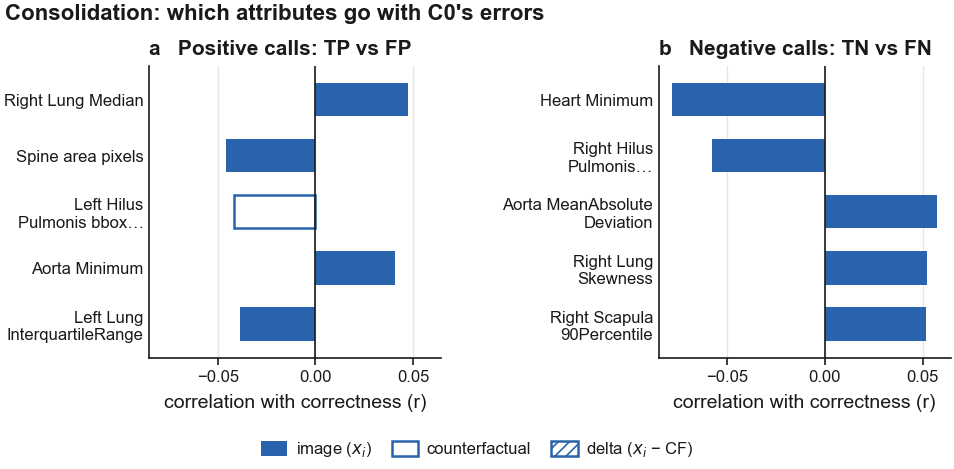

In [5]:
N_KEEP         = 5
MAX_REDUNDANCY = 0.6

def select(ranking, rows):
    """Top N_KEEP attributes of `ranking` whose pairwise |r| on `rows` stays below MAX_REDUNDANCY."""
    d, kept = data[rows], []
    for a in ranking["attribute"]:
        if all(abs(d[a].corr(d[s])) < MAX_REDUNDANCY for s in kept):
            kept.append(a)
        if len(kept) == N_KEEP:
            break
    return kept

def short(f):
    """Readable label: 'Heart_original_firstorder_Mean' -> 'Heart Mean'."""
    s = f.replace("delta_", "Δ ").replace("_original_", " ").replace("firstorder_", "")
    return s.replace("shape2D_", "shape ").replace("_", " ")

selected = {p: select(corr[p], pred == p) for p in SIDES}

# One bar per attribute: its strongest form's r. One hue (attributes blue); the form is the fill,
# as in the dumbbells: solid = image, hollow = counterfactual, hatched = delta.
import textwrap

BLUE        = FAMILY["attr"]
FORM_STYLE  = {"image": dict(color=BLUE),
               "CF":    dict(facecolor="white", edgecolor=BLUE, lw=0.9),
               "delta": dict(facecolor="white", edgecolor=BLUE, lw=0.9, hatch="//////")}
FORM_LABELS = {"image": r"image ($x_i$)", "CF": "counterfactual", "delta": r"delta ($x_i$ − CF)"}
SIDE_TITLE  = {1: "Positive calls: TP vs FP", 0: "Negative calls: TN vs FN"}
SIDE_SQ     = 36 * MM                                        # square panel
plt.rcParams["hatch.linewidth"] = 0.6

def wrap(s, width=18):
    """Long labels on two lines, so they do not squeeze the square panels."""
    return "\n".join(textwrap.wrap(s, width, max_lines=2, placeholder="…"))

fig, axes = plt.subplots(1, 2, figsize=(2 * SIDE_SQ + 56 * MM, SIDE_SQ + 24 * MM), sharex=True,
                         layout="constrained")
fig.get_layout_engine().set(w_pad=1 * MM, h_pad=1 * MM, wspace=0.02)
for ax, letter, p in zip(axes, "ab", SIDES):
    top = corr[p].set_index("attribute").loc[selected[p][::-1]]      # best-ranked on top
    y   = np.arange(len(top))
    for yi, (r, form) in zip(y, top[["r_best", "best form"]].itertuples(index=False)):
        ax.barh(yi, r, height=0.6, **FORM_STYLE[form])
    ax.set_yticks(y, [wrap(short(a)) for a in top.index])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(top) - 0.4)
    ax.axvline(0, color=INK, lw=LW["axis"])
    ax.grid(axis="x"); ax.set_axisbelow(True)
    ax.set_title(f"{letter}   {SIDE_TITLE[p]}", loc="left")
    ax.set_xlabel("correlation with correctness (r)")
    ax.set_box_aspect(1)                                     # square panels, as everywhere
fig.suptitle(f"{DISEASE.capitalize()}: which attributes go with C0's errors", x=0.01, ha="left")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, **FORM_STYLE[f]) for f in FORM_STYLE],
           labels=list(FORM_LABELS.values()), loc="outside lower center", ncol=3,
           handlelength=1.6, handleheight=1.0, columnspacing=1.2)
save(fig, "attribute_correlations")
plt.show()


In [6]:
# Print the correlations between the top attributes and the target for each form
for p, title in SIDES.items():
    print(f"{title}:")
    top = corr[p].set_index("attribute").loc[selected[p]]
    display(top[[f"r_{f}" for f in FORMS]].round(3))

C0 says positive (TP vs FP):


,r_image,r_CF,r_delta
attribute,,,
Right Lung_original_firstorder_Median,0.047,0.028,0.031
Spine_area_pixels,-0.045,-0.043,-0.011
Left Hilus Pulmonis_bbox_width,-0.037,-0.042,0.005
Aorta_original_firstorder_Minimum,0.041,0.034,0.012
Left Lung_original_firstorder_InterquartileRange,-0.039,-0.028,-0.018


C0 says negative (TN vs FN):


,r_image,r_CF,r_delta
attribute,,,
Heart_original_firstorder_Minimum,-0.078,-0.054,-0.024
Right Hilus Pulmonis_original_firstorder_10Percentile,-0.058,-0.045,-0.022
Aorta_original_firstorder_MeanAbsoluteDeviation,0.058,0.046,0.022
Right Lung_original_firstorder_Skewness,0.052,0.031,0.019
Right Scapula_original_firstorder_90Percentile,0.052,0.046,0.014


## 5. Quadrant profiles: image vs counterfactual

One row per side, one panel per outcome: **TP | FP** on the positive side's attributes, and
**TN | FN** on the negative side's. Each attribute is a dumbbell:

* **filled dot**: the image's average value in that quadrant
* **hollow dot**: the average value of those images' counterfactuals
* **the line between them**: the average difference, i.e. what separates the image from its
  nearest image of the other class. A short line means the two agree on that attribute.

Colour is the organ. Read across a row: where do the correct and the wrong calls differ, and do
they differ in the image, in the counterfactual, or in the gap between them?

**Units: SD.** Raw units differ per attribute (pixel areas, intensities, ratios), so both the
image and the counterfactual values are z-scored with the **same** mean and SD (those of the
images), which puts both dots on one axis and makes the line length the difference in SD units.
0 = the average image.

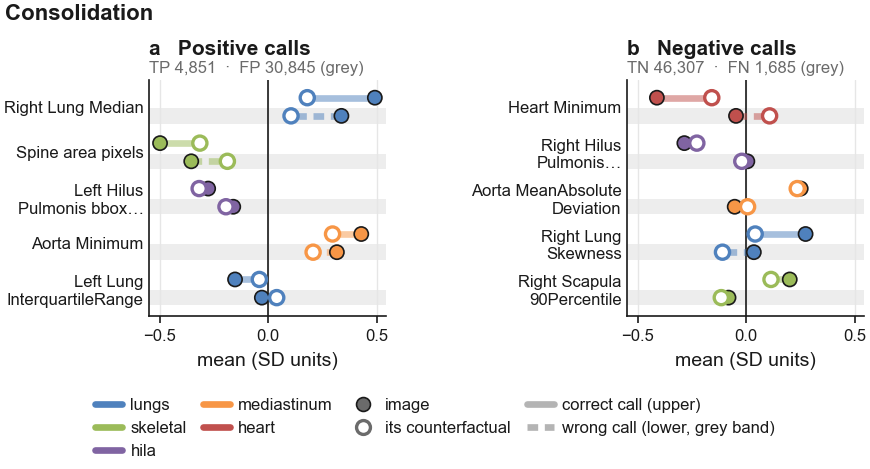

In [7]:
true = data[f"{DISEASE}_true"].astype(int)
quadrant = np.select([(pred == 1) & (true == 1), (pred == 1) & (true == 0),
                      (pred == 0) & (true == 0)], ["TP", "FP", "TN"], "FN")
n_per_q = pd.Series(quadrant).value_counts()
ROWS = {1: ["TP", "FP"], 0: ["TN", "FN"]}     # side -> (correct, wrong) quadrant

# SD units: image and CF values z-scored with the image mean/SD, so both share one axis.
used = list(dict.fromkeys(selected[1] + selected[0]))
mu, sd = data[used].mean(), data[used].std()
zq = (data[used] - mu) / sd                                                        # image
zc = (data[[f"cf_attr_{a}" for a in used]].set_axis(used, axis=1) - mu) / sd       # its CF

# One colour per anatomical group; first match wins, anything else (global ratios, demographics) is grey.
ORGAN_GROUPS = {
    "heart":       (["Heart"],                            "#C0504D"),
    "lungs":       (["Left Lung", "Right Lung"],          "#4F81BD"),
    "hila":        (["Hilus"],                            "#8064A2"),
    "mediastinum": (["Mediastinum", "Aorta", "Weasand"],  "#F79646"),
    "skeletal":    (["Scapula", "Clavicle", "Spine"],     "#9BBB59"),
    "diaphragm":   (["Facies Diaphragmatica"],            "#4BACC6"),
}
def organ_group(f):
    return next((g for g, (keys, _) in ORGAN_GROUPS.items() if any(k in f for k in keys)), "other")
def organ_color(f):
    g = organ_group(f)
    return ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6"

# Dumbbell sizes at print scale: marker area in pt^2, line widths in pt.
DB = {"line": 2.4, "dot": 26, "edge": 0.6, "hollow": 1.2}

def dumbbell(ax, attrs, img, cf, alpha=1.0, scale=1.0):
    """One row per attribute: filled dot = image, hollow dot = counterfactual, line = the difference."""
    y = np.arange(len(attrs))
    colors = [organ_color(a) for a in attrs]
    for yi, a, c in zip(y, attrs, colors):
        ax.plot([img[a], cf[a]], [yi, yi], color=c, lw=DB["line"] * scale, alpha=0.5 * alpha,
                solid_capstyle="butt", zorder=2)
    ax.scatter(img[attrs], y, s=DB["dot"] * scale, color=colors, edgecolor=INK,
               lw=DB["edge"], alpha=alpha, zorder=3)
    ax.scatter(cf[attrs], y, s=DB["dot"] * scale, facecolor="white", edgecolor=colors,
               lw=DB["hollow"] * scale, alpha=alpha, zorder=3)
    ax.set_yticks(y, [wrap(short(a)) for a in attrs])
    ax.tick_params(axis="y", length=0)
    ax.axvline(0, color=INK, lw=LW["axis"], zorder=1)
    ax.grid(axis="x"); ax.set_axisbelow(True)
    ax.set_ylim(-0.6, len(attrs) - 0.4)                   # half a row of air, no more
    ax.set_box_aspect(1)                                  # square panels, everywhere

groups = list(dict.fromkeys(organ_group(a) for a in used))
organ_handles = [plt.Line2D([], [], color=ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6",
                            lw=DB["line"]) for g in groups]
style_handles = [plt.Line2D([], [], marker="o", ls="", ms=5, color=MUTED, markeredgecolor=INK,
                            markeredgewidth=DB["edge"]),
                 plt.Line2D([], [], marker="o", ls="", ms=5, markerfacecolor="white",
                            markeredgecolor=MUTED, markeredgewidth=DB["hollow"])]
STYLE_LABELS = ["image", "its counterfactual"]

def add_legends(fig, attrs=None):
    """One legend row under the figure: the organ colours (of `attrs`, default the selected
    attributes), then the two dot styles."""
    gs = groups if attrs is None else list(dict.fromkeys(organ_group(a) for a in attrs))
    handles = [plt.Line2D([], [], color=ORGAN_GROUPS[g][1] if g != "other" else "#A6A6A6",
                          lw=DB["line"]) for g in gs]
    fig.legend(handles=handles + style_handles, labels=gs + STYLE_LABELS,
               loc="outside lower center", ncol=len(gs) + 2)

SQUARE = 34 * MM                                          # side of one square dumbbell panel

def panel_height(n_rows):
    """Figure height (inches) for n_rows stacked square dumbbell panels: titles, x label, legend."""
    return n_rows * (SQUARE + 7 * MM) + 14 * MM

def tighten(fig):
    """Less padding between constrained-layout panels than the matplotlib default."""
    fig.get_layout_engine().set(w_pad=1 * MM, h_pad=1 * MM, wspace=0.02, hspace=0.04)

# ── Correct vs wrong calls in one panel per side ──
WRONG_BG = "#EDEDED"                                      # light grey behind the wrong-call rows
WRONG_LS = (0, (1.6, 1.0))                                # dashes, in units of the line width
OFF      = 0.2                                            # half the gap between the two sub-rows

def dumbbell_pair(ax, attrs, right, wrong):
    """Per attribute two dumbbells: the correct calls on top in full colour, the wrong calls below,
    greyed, dashed and on a grey band. right / wrong: (image means, CF means)."""
    y = np.arange(len(attrs))
    for yi in y:
        ax.axhspan(yi - OFF - 0.17, yi - OFF + 0.17, color=WRONG_BG, lw=0, zorder=0)
    colors = [organ_color(a) for a in attrs]
    for (img, cf), dy, ls in [(right, OFF, "-"), (wrong, -OFF, WRONG_LS)]:
        for yi, a, c in zip(y + dy, attrs, colors):
            ax.plot([img[a], cf[a]], [yi, yi], color=c, lw=DB["line"], alpha=0.5, ls=ls,
                    solid_capstyle="butt", dash_capstyle="butt", zorder=2)
        ax.scatter(img[attrs], y + dy, s=DB["dot"], color=colors, edgecolor=INK, lw=DB["edge"], zorder=3)
        ax.scatter(cf[attrs], y + dy, s=DB["dot"], facecolor="white", edgecolor=colors,
                   lw=DB["hollow"], zorder=3)
    ax.set_yticks(y, [wrap(short(a)) for a in attrs])
    ax.tick_params(axis="y", length=0)
    ax.axvline(0, color=INK, lw=LW["axis"], zorder=1)
    ax.grid(axis="x"); ax.set_axisbelow(True)
    ax.set_ylim(-0.6, len(attrs) - 0.4)
    ax.set_box_aspect(1)                                  # square panels, everywhere

q_img, q_cf = zq.groupby(quadrant).mean(), zc.groupby(quadrant).mean()

SIDE_NAME = {1: "Positive calls", 0: "Negative calls"}
fig, axes = plt.subplots(1, 2, figsize=(2 * SQUARE + 52 * MM, SQUARE + 26 * MM), sharex=True,
                         layout="constrained")
tighten(fig)
for ax, letter, (p, (q_ok, q_bad)) in zip(axes, "ab", ROWS.items()):
    attrs = selected[p][::-1]                               # best-ranked attribute on top
    dumbbell_pair(ax, attrs, (q_img.loc[q_ok], q_cf.loc[q_ok]), (q_img.loc[q_bad], q_cf.loc[q_bad]))
    ax.set_title(f"{letter}   {SIDE_NAME[p]}", loc="left", pad=9)
    ax.text(0, 1.015, f"{q_ok} {n_per_q[q_ok]:,}  ·  {q_bad} {n_per_q[q_bad]:,} (grey)",
            transform=ax.transAxes, fontsize=FS["small"], color=MUTED, va="bottom")
    ax.set_xlabel("mean (SD units)")
fig.suptitle(f"{DISEASE.capitalize()}", x=0.01, ha="left")
fig.legend(handles=organ_handles + style_handles
                   + [plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5),
                      plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5, ls=WRONG_LS)],
           labels=groups + STYLE_LABELS + ["correct call (upper)", "wrong call (lower, grey band)"],
           loc="outside lower center", ncol=4, columnspacing=1.0)
save(fig, "quadrant_profiles")
plt.show()


## 6. Groups in a C2 embedding, described by attribute profiles

A C2 MLP, trained to predict whether C0's call is correct, already maps every image into a space
organised by correctness: its last hidden layer (16 units, what the output layer reads). Per side
of C0's call, the images are clustered there with k-means, and each group is described
**afterwards** by its **profile**: the group's mean minus the side's mean, per attribute, as image,
counterfactual and delta (SD units). *What do the images in this group look like?* The top
non-redundant attributes are drawn as dumbbells, as in step 5.

The embeddings come from `code/c2_embed_attributes.py`: the C2 I+C+D model (it reproduces the
published fold-4 scores exactly, and also sees C0's image embeddings, so its groups can rest on
things no attribute measures), fit on folds 0-3 and run on fold 4 only, because the five CV models
do not share an embedding space. So only fold 4's ~18k images are grouped here. Each image's
embedding is the one of its pair with the nearest counterfactual, the same pair the attributes
above describe. The held-out check splits fold 4 by patient: k-means is fit on one half, the other
is only assigned.

Checks per group, in the table:
* **error rate** against the side's base rate: groups that all sit near the base rate are
  image types, not failure modes.
* **error rate (held-out)**: on the half k-means did not see. If a group's error rate holds there,
  it is not a fitting artefact.
* **mean C2 percentile**: does C2's quality score agree with the group's track record? High-error
  groups should sit low (C2 distrusts them) and low-error groups high.
* **mean MSP** (threshold variant, C0's confidence in its own call): if the high-error group is
  also the low-MSP one, it is the same information MSP already has. A high-error group with
  ordinary MSP is the interesting case: confidently wrong, and describable.
* **C2 AUROC / MSP AUROC inside the group**: how well each score still ranks right vs wrong calls
  among the group's images. A group where C2 beats MSP is where C2 adds something MSP does not.

Groups are named **group A, B, C...** by error rate, A the lowest (not C1, C2..., which would
clash with the model names).

First a check: if PC1 of the embedding explains nearly all its variance and tracks the MLP's score,
the embedding is close to one-dimensional, and the groups are little more than bins of the score.


In [8]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from c2_msp import msp_score

EMB_LAYER  = "h16"     # "h16": the last hidden layer | "h32": the one before
EMB_FOLD   = 4         # the fold the MLP was NOT trained on (c2_embed_attributes.py --fold)
N_CLUSTERS = 3

# C0 confidence per image: threshold MSP, from C0's probability and its Youden threshold.
c0_t = float(open(os.path.join(RESULTS, "C0_final", "multilabel_ignore", DISEASE, "threshold.txt")).read())
msp  = msp_score(data[f"{DISEASE}_prob"].values, c0_t, "threshold")

# C2's quality score as a percentile WITHIN C0's call (0 = least trusted, 1 = most trusted):
# the raw score is class-balanced, not calibrated, so only its rank is meaningful.
data["c2_pct"] = data.groupby(pred)["model_score"].rank(pct=True)

def GROUP(k, n=None):
    """Cluster id -> display name: 'group A' is the lowest error rate, then B, C... (n groups,
    default N_CLUSTERS)."""
    return f"group {'ABCDEFGHIJ'[(n or N_CLUSTERS) - k]}"

def summarise_groups(title, rows, labels, held_out, n):
    """Renumber k-means labels 1..n by error rate on the fitting rows (1 = most errors), show the
    group table and return the group id per row."""
    d = pd.DataFrame({"cluster": labels, "error": 1 - data.loc[rows, "correct"].values,
                      "msp": msp[rows], "c2": data.loc[rows, "c2_pct"].values,
                      "score": data.loc[rows, "model_score"].values, "held_out": held_out})
    order = d[~d.held_out].groupby("cluster")["error"].mean().sort_values(ascending=False).index
    d["cluster"] = d["cluster"].map({c: i + 1 for i, c in enumerate(order)})

    def auroc(x, col):                 # how well a score ranks right vs wrong calls within x
        return roc_auc_score(1 - x["error"], x[col]) if x["error"].nunique() == 2 else np.nan

    g = d.groupby("cluster")
    table = pd.DataFrame({
        "n":                        g.size(),
        "error rate":               g["error"].mean(),
        "error rate (held-out)":    d[d.held_out].groupby("cluster")["error"].mean(),
        "mean C2 percentile":       g["c2"].mean(),
        "mean MSP":                 g["msp"].mean(),
        "C2 AUROC":                 pd.Series({k: auroc(x, "score") for k, x in g}),
        "MSP AUROC":                pd.Series({k: auroc(x, "msp") for k, x in g}),
    })
    print(f"{title}: base error rate {d['error'].mean():.3f}, base mean MSP {d['msp'].mean():.3f}, "
          f"AUROC C2 {auroc(d, 'score'):.3f} / MSP {auroc(d, 'msp'):.3f}")
    table.index = table.index.map(lambda k: GROUP(k, n))
    display(table.sort_index().round(3))
    return pd.Series(d["cluster"].values, index=rows)

f = np.load(os.path.join(C2, DISEASE, SOURCE, f"cf_{BEST_K}", "attributes_embeddings",
                         f"fold_{EMB_FOLD}", "full.npz"))
emb_rows = pd.Index(pd.Series(data.index, index=data["path"]).loc[f["paths"]].values)
assert (data.loc[emb_rows, "correct"].values == f["correct"]).all(), "rows do not line up"

H    = f[EMB_LAYER][:, 0]                                 # slot 0: the pair with the nearest CF
live = H.std(axis=0) > 0                                   # dead ReLU units carry nothing
EMB  = pd.DataFrame(H[:, live], index=emb_rows)
emb_prob = pd.Series(f["slot_probs"][:, 0], index=emb_rows)
print(f"C2 MLP, {EMB_LAYER}: {live.sum()}/{len(live)} live units, "
      f"{len(EMB):,} images of fold {EMB_FOLD} | its AUROC "
      f"{roc_auc_score(data.loc[emb_rows, 'correct'], emb_prob):.4f}")

def cluster_space(p, idx):
    """The clustering features of rows `idx`: their embedding (the same space on both sides)."""
    return EMB.loc[idx].values

# Is the embedding close to one-dimensional?
for p, title in SIDES.items():
    rows = emb_rows[(pred.loc[emb_rows] == p).values]
    pca  = PCA().fit(EMB.loc[rows])
    pc1  = pca.transform(EMB.loc[rows])[:, 0]
    print(f"{title}: variance in PC1-3 {np.round(pca.explained_variance_ratio_[:3], 3)} | "
          f"|r(PC1, MLP score)| = {abs(np.corrcoef(pc1, emb_prob.loc[rows])[0, 1]):.3f}")

# Held-out check inside fold 4: k-means fit on one patient-disjoint half, the other only assigned.
fit_half = pd.Series(False, index=emb_rows)
tr, _ = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
             .split(emb_rows, groups=data.loc[emb_rows, "patient_id"]))
fit_half.iloc[tr] = True

cluster = {}                                   # side -> group id per row (1 = most errors)
for p, title in SIDES.items():
    rows   = emb_rows[(pred.loc[emb_rows] == p).values]
    X      = cluster_space(p, rows)
    fit    = fit_half.loc[rows].values
    labels = KMeans(N_CLUSTERS, n_init=10, random_state=42).fit(X[fit]).predict(X)
    cluster[p] = summarise_groups(title, rows, labels, ~fit, N_CLUSTERS)


C2 MLP, h16: 13/16 live units, 17,017 images of fold 4 | its AUROC 0.9463
C0 says positive (TP vs FP): variance in PC1-3 [0.514 0.275 0.074] | |r(PC1, MLP score)| = 0.762
C0 says negative (TN vs FN): variance in PC1-3 [0.719 0.118 0.058] | |r(PC1, MLP score)| = 0.765


C0 says positive (TP vs FP): base error rate 0.866, base mean MSP 0.131, AUROC C2 0.619 / MSP 0.635


,n,error rate,error rate (held-out),mean C2 percentile,mean MSP,C2 AUROC,MSP AUROC
group A,2638,0.826,0.826,0.677,0.151,0.598,0.632
group B,1950,0.868,0.866,0.458,0.143,0.626,0.607
group C,2558,0.907,0.900,0.306,0.100,0.529,0.602


C0 says negative (TN vs FN): base error rate 0.035, base mean MSP 0.970, AUROC C2 0.709 / MSP 0.705


,n,error rate,error rate (held-out),mean C2 percentile,mean MSP,C2 AUROC,MSP AUROC
group A,2981,0.010,0.011,0.848,0.987,0.630,0.627
group B,4386,0.032,0.035,0.502,0.969,0.643,0.650
group C,2504,0.067,0.068,0.161,0.951,0.562,0.581


In [9]:
# Attribute vectors per embedding group. Every attribute z-scored as in step 5 (image mean/SD).
mu_all, sd_all = data[ATTR_COLS].mean(), data[ATTR_COLS].std().replace(0, 1)
ZQ = (data.loc[emb_rows, ATTR_COLS] - mu_all) / sd_all
ZC = (data.loc[emb_rows, CF_COLS].set_axis(ATTR_COLS, axis=1) - mu_all) / sd_all
mask = lambda idx: data.index.isin(idx)                     # row index -> boolean mask over data

def profile(p, in_k):
    """Profile vector: group mean minus side mean per attribute, as image, CF and delta (SD units),
    ranked by its strongest form."""
    rows = cluster[p].index
    img  = ZQ.loc[in_k].mean() - ZQ.loc[rows].mean()
    cf   = ZC.loc[in_k].mean() - ZC.loc[rows].mean()
    out  = pd.DataFrame({"attribute": ATTR_COLS, "image": img.values, "CF": cf.values,
                         "delta": (img - cf).values})
    v    = out[list(FORMS)].to_numpy()
    best = np.abs(v).argmax(axis=1)
    out["best form"] = np.array(list(FORMS))[best]
    out["best"]      = v[np.arange(len(out)), best]
    return out.sort_values("best", key=abs, ascending=False, ignore_index=True)

PROFILE, PROFILE_ATTRS = {}, {}
for p, title in SIDES.items():
    rows = cluster[p].index
    for k in range(N_CLUSTERS, 0, -1):                   # group A first
        in_k = rows[(cluster[p] == k).values]
        PROFILE[p, k] = profile(p, in_k)
        PROFILE_ATTRS.setdefault(p, {})[k] = select(PROFILE[p, k], mask(in_k))

        err = 1 - data.loc[in_k, "correct"].mean()
        print(f"\n{title}, {GROUP(k)} (n = {len(in_k):,}, error {err:.1%}): profile (SD units)")
        display(PROFILE[p, k].set_index("attribute").loc[PROFILE_ATTRS[p][k], list(FORMS)].round(3))

# The step-5 z-frames gain the attributes the embedding groups are described by, so the dumbbells,
# t-SNE map and case cards can draw them.
extra = [a for a in dict.fromkeys(a for p in PROFILE_ATTRS for k in PROFILE_ATTRS[p]
                                  for a in PROFILE_ATTRS[p][k]) if a not in zq.columns]
zq = pd.concat([zq, (data[extra] - mu_all[extra]) / sd_all[extra]], axis=1)
zc = pd.concat([zc, (data[[f"cf_attr_{a}" for a in extra]].set_axis(extra, axis=1)
                     - mu_all[extra]) / sd_all[extra]], axis=1)

held_out = (~fit_half).reindex(data.index, fill_value=False)     # the half k-means did not see

def group_attrs(p, k):
    """The attributes drawn for group k on side p: the group's profile attributes."""
    return PROFILE_ATTRS[p][k]



C0 says positive (TP vs FP), group A (n = 2,638, error 82.6%): profile (SD units)


,image,CF,delta
attribute,,,
Weasand_bbox_width,-0.352,-0.344,-0.009
Spine_original_firstorder_Entropy,-0.318,-0.276,-0.042
cardiothoracic_ratio,-0.316,-0.215,-0.101
Left Lung_original_firstorder_10Percentile,0.315,0.223,0.093
mediastinal_ratio,-0.294,-0.245,-0.049



C0 says positive (TP vs FP), group B (n = 1,950, error 86.8%): profile (SD units)


,image,CF,delta
attribute,,,
Heart_original_firstorder_Entropy,0.085,0.191,-0.106
Mediastinum_original_shape2D_Sphericity,0.118,0.157,-0.040
Heart_original_shape2D_Sphericity,0.090,0.148,-0.058
Left Lung_original_shape2D_Sphericity,0.071,-0.067,0.138
Heart_original_shape2D_Elongation,0.130,0.070,0.061



C0 says positive (TP vs FP), group C (n = 2,558, error 90.7%): profile (SD units)


,image,CF,delta
attribute,,,
Weasand_bbox_width,0.338,0.335,0.004
Mediastinum_original_shape2D_MinorAxisLength,0.274,0.282,-0.008
Mediastinum_original_firstorder_Minimum,-0.273,-0.247,-0.026
Aorta_original_shape2D_Elongation,0.269,0.267,0.002
Left Clavicle_original_firstorder_Minimum,-0.251,-0.268,0.017


... (2 outputs left out)


C0 says negative (TN vs FN), group B (n = 4,386, error 3.2%): profile (SD units)


,image,CF,delta
attribute,,,
Heart_original_firstorder_InterquartileRange,-0.099,-0.047,-0.052
Left Lung_original_firstorder_InterquartileRange,0.081,0.033,0.048
age_pred,0.075,0.032,0.043
Right Scapula_original_firstorder_InterquartileRange,-0.065,-0.042,-0.023
Heart_original_firstorder_Kurtosis,0.065,0.028,0.038



C0 says negative (TN vs FN), group C (n = 2,504, error 6.7%): profile (SD units)


,image,CF,delta
attribute,,,
Heart_original_firstorder_Variance,-0.576,-0.322,-0.254
Right Lung_original_firstorder_Skewness,-0.462,-0.290,-0.172
Right Hilus Pulmonis_original_firstorder_Median,0.436,0.312,0.123
Aorta_original_firstorder_Minimum,0.410,0.349,0.061
Right Hilus Pulmonis_original_firstorder_Minimum,0.366,0.313,0.053


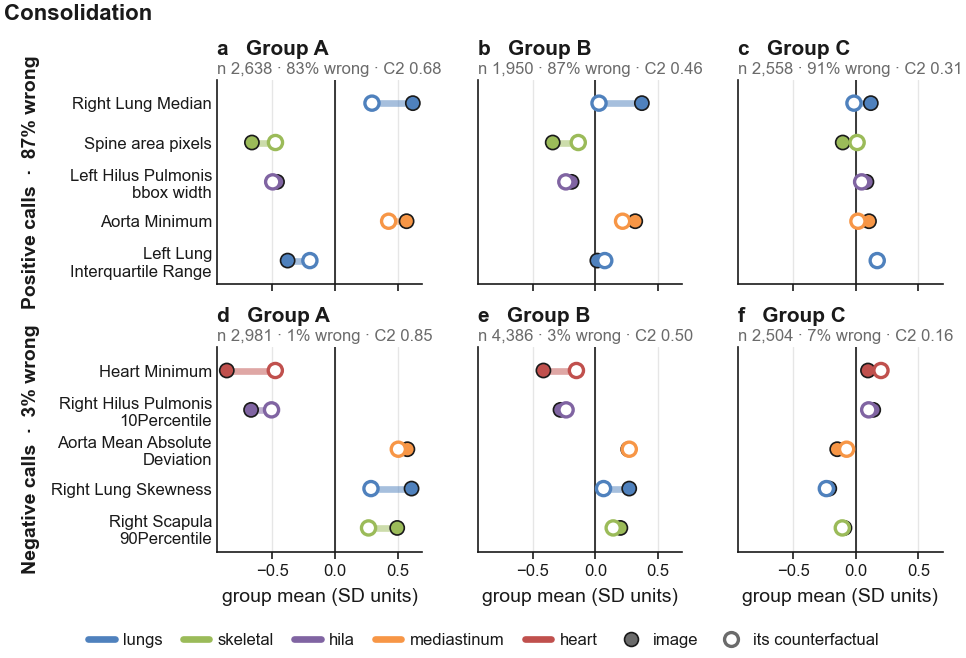

In [10]:
# Embedding groups: one row per side of C0's call, one column per group (A = lowest error rate).
# Every panel shows the side's selected attributes (step 4), image vs counterfactual (SD units),
# so the groups of one side can be compared row by row.
import re, textwrap

def full_label(a, width=22):
    """The full attribute name, camelCase split into words so it can wrap: never abbreviated."""
    s = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", short(a))
    return "\n".join(textwrap.wrap(s, width))

GROUP_SQ  = 26 * MM                                       # smaller squares: one dumbbell per row
n         = N_CLUSTERS
SIDE_NAME = {1: "Positive calls", 0: "Negative calls"}

fig, axes = plt.subplots(2, n, figsize=(n * GROUP_SQ + 46 * MM, 2 * (GROUP_SQ + 8 * MM) + 16 * MM),
                         sharex=True, sharey="row", layout="constrained")
tighten(fig)
letters = iter("abcdefghij")
for row, p in zip(axes, SIDES):
    rows  = cluster[p].index
    base  = 1 - data.loc[rows, "correct"].mean()
    attrs = selected[p][::-1]                               # best-ranked attribute on top
    for ax, k in zip(row, range(n, 0, -1)):                 # id 1 = most errors, so group A first
        in_k = rows[(cluster[p] == k).values]
        dumbbell(ax, attrs, zq.loc[in_k].mean(), zc.loc[in_k].mean())
        ax.set_title(f"{next(letters)}   {GROUP(k, n).replace('group', 'Group')}", loc="left", pad=9)
        ax.text(0, 1.015, f"n {len(in_k):,} · {1 - data.loc[in_k, 'correct'].mean():.0%} wrong · "
                          f"C2 {data.loc[in_k, 'c2_pct'].mean():.2f}",
                transform=ax.transAxes, fontsize=FS["small"], color=MUTED, va="bottom")
    row[0].set_yticklabels([full_label(a) for a in attrs])  # labels once per side
    row[0].set_ylabel(f"{SIDE_NAME[p]}  ·  {base:.0%} wrong", fontweight="bold", labelpad=4)
    for ax in row[1:]:
        ax.tick_params(axis="y", labelleft=False)
fig.align_ylabels(axes[:, 0])                               # side labels in one column, whatever the label widths
for ax in axes[-1]:
    ax.set_xlabel("group mean (SD units)")
fig.suptitle(f"{DISEASE.capitalize()}",
             x=0.01, ha="left")
add_legends(fig)
save(fig, "embedding_group_profiles")
plt.show()




### Groups on a t-SNE map

The same images, embedded with t-SNE in the space the groups were found in (the C2 embedding of
step 6). One row per side of
C0's call, and the same map coloured three ways:

* **group**: which group k-means put each image in
* **C0 outcome**: whether C0's call was right (green) or wrong (red)
* **C2 percentile**: C2's quality score, green = trusted, red = distrusted

Read across a row: if the explanation supports C2, the high-error group, the red outcomes and the
low C2 percentiles should concentrate in the same regions.

Two cautions. The groups are a partition of continuous data, not separate blobs, so expect
adjacent regions rather than islands. And t-SNE keeps local neighbourhoods but not global
distances or areas: the size of a region and the gap between regions mean nothing. A random
sample of `TSNE_N` images per side is embedded, because t-SNE is slow.

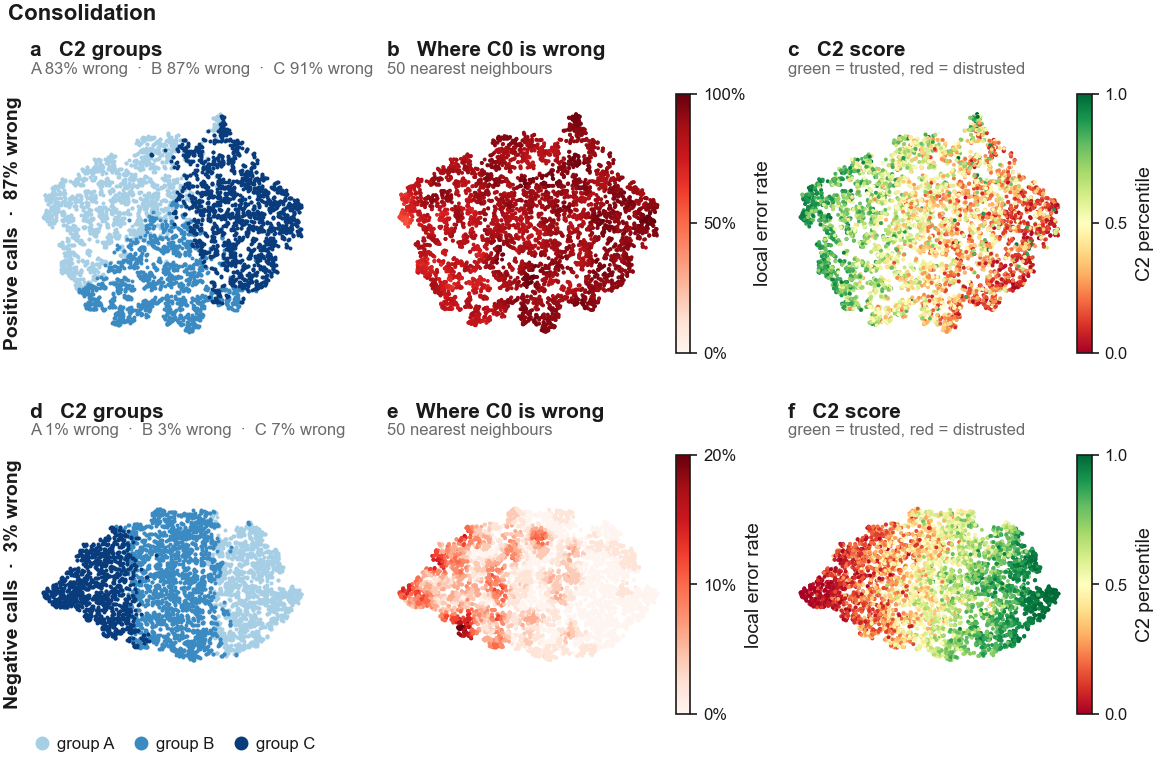

In [11]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from matplotlib.ticker import PercentFormatter

TSNE_N  = 5000                                   # images per side (t-SNE is O(n log n) but slow)
LOCAL_K = max(10, TSNE_N // 100)                 # neighbours on the map for the local error rate
TSNE_SQ = 36 * MM                                # square map panel
GROUP_COLORS = dict(zip(range(N_CLUSTERS, 0, -1),                      # group A (lowest error) light
                        plt.cm.Blues(np.linspace(0.35, 0.95, N_CLUSTERS))))

TSNE_MAP = {}                                    # side -> (sampled rows, 2-D embedding), reused by the case cards

def tsne_position(p, row, n_nn=10):
    """Where `row` sits on side p's map. t-SNE cannot place a new point, so a row outside the
    sample is put at the mean position of its n_nn nearest sampled neighbours in the clustering space."""
    idx, emb = TSNE_MAP[p]
    j = idx.get_indexer([row])[0]
    if j >= 0:
        return emb[j]
    d = np.linalg.norm(cluster_space(p, idx) - cluster_space(p, [row])[0], axis=1)
    return emb[np.argsort(d)[:n_nn]].mean(axis=0)

SIDE_NAME = {1: "Positive calls", 0: "Negative calls"}
CBAR      = dict(shrink=0.8, aspect=18, pad=0.02)    # thin colour bars, close to their panel

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 3, figsize=(3 * TSNE_SQ + 40 * MM, 2 * (TSNE_SQ + 8 * MM) + 10 * MM),
                         layout="constrained")

tighten(fig)
letters = iter("abcdef")
for row, p in zip(axes, SIDES):
    rows = cluster[p].index
    idx  = rows[rng.choice(len(rows), min(TSNE_N, len(rows)), replace=False)]
    emb  = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(
        cluster_space(p, idx))
    TSNE_MAP[p] = (idx, emb)
    kw   = dict(s=2, lw=0, rasterized=True)
    errs = {k: 1 - data.loc[rows[(cluster[p] == k).values], "correct"].mean()
            for k in range(N_CLUSTERS, 0, -1)}

    # C2 groups; their error rates go in the muted subtitle, the colours in the figure legend
    ax = row[0]
    for k in errs:
        m = (cluster[p].loc[idx] == k).values
        ax.scatter(*emb[m].T, color=GROUP_COLORS[k], **kw)
    ax.set_title(f"{next(letters)}   C2 groups", loc="left", pad=9)
    ax.text(0, 1.015, "  ·  ".join(f"{GROUP(k)[-1]} {e:.0%} wrong" for k, e in errs.items()),
            transform=ax.transAxes, fontsize=FS["small"], color=MUTED, va="bottom")
    ax.set_ylabel(f"{SIDE_NAME[p]}  ·  {1 - data.loc[rows, 'correct'].mean():.0%} wrong",
                  fontweight="bold")

    # Where C0 is wrong: error rate among each point's LOCAL_K nearest neighbours on the map
    ax = row[1]
    _, nb = NearestNeighbors(n_neighbors=LOCAL_K).fit(emb).kneighbors(emb)
    local_err = 1 - data.loc[idx, "correct"].values[nb].mean(axis=1)
    vmax = 1.0 if p == 1 else 0.2                # negative calls: errors are rare, so a tighter scale
    sc = ax.scatter(*emb.T, c=local_err, cmap="Reds", vmin=0, vmax=vmax, **kw)
    fig.colorbar(sc, ax=ax, ticks=np.linspace(0, vmax, 3),
                 format=PercentFormatter(xmax=1, decimals=0), label="local error rate", **CBAR)
    ax.set_title(f"{next(letters)}   Where C0 is wrong", loc="left", pad=9)
    ax.text(0, 1.015, f"{LOCAL_K} nearest neighbours", transform=ax.transAxes,
            fontsize=FS["small"], color=MUTED, va="bottom")

    # C2 percentile
    ax = row[2]
    sc = ax.scatter(*emb.T, c=data.loc[idx, "c2_pct"], cmap="RdYlGn", vmin=0, vmax=1, **kw)
    fig.colorbar(sc, ax=ax, ticks=[0, 0.5, 1], label="C2 percentile", **CBAR)
    ax.set_title(f"{next(letters)}   C2 score", loc="left", pad=9)
    ax.text(0, 1.015, "green = trusted, red = distrusted", transform=ax.transAxes,
            fontsize=FS["small"], color=MUTED, va="bottom")

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_box_aspect(1)                         # square panels, as everywhere
fig.align_ylabels(axes[:, 0])
fig.suptitle(f"{DISEASE.capitalize()}", x=0.01, ha="left")
axes[1, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=4, color=GROUP_COLORS[k])
                           for k in range(N_CLUSTERS, 0, -1)],
                  labels=[GROUP(k) for k in range(N_CLUSTERS, 0, -1)],
                  loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=N_CLUSTERS, frameon=False,
                  handletextpad=0.1, columnspacing=0.8, borderaxespad=0.2)
save(fig, "tsne_groups_embedding")
plt.show()


## 7. Case cards

One image taken through the pipeline, one panel per step, in the order the pipeline runs:

| panel | step |
|---|---|
| **a** C0's call | the input X-ray (organs outlined): what C0 predicts, and with what probability |
| **b** Counterfactual | its nearest image of the other class, and C0's probability for it |
| **c** What changes | the group's profile attributes, image (filled) vs counterfactual (hollow): the line is the delta; faint = the group's average |
| **d** Assigned group | where the image falls on the t-SNE map of the groups (the same map as above) |
| **e** Similar members | four typical members of its group, organs outlined, tagged with their outcome |
| **f** How the group performs | the error rate of every group for this kind of call; the image's group coloured |
| **g** C2's quality score | the image's C2 score against all calls of the same kind, split by C0 right / wrong |

The title reads the same chain in words. On the t-SNE panel, an image outside the t-SNE sample is
placed at the mean position of its 10 nearest sampled neighbours in the clustering space (t-SNE
cannot embed a new point).

`pick_case` chooses the example automatically: a **held-out** image (so its group was fit without
it: the half of fold 4 k-means did not see), with the wanted outcome, among the most typical half of its group, with the
clearest assignment. `c2="agree"` (default) keeps images where C2 clearly points the right way
(top third of C2 percentiles for a correct call, bottom third for a wrong one); `c2="disagree"`
shows the opposite, and `c2=None` ignores C2. It prints the runners-up; pass any of their row
numbers to `case_card` instead.

In [12]:
#OLD CARDS SAVED HERE
from scipy.stats import gaussian_kde
from sklearn.metrics import roc_auc_score

DATA_ROOT      = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
LETTERS        = "ABCDEFGHIJ"
SEG_ON_TYPICAL = True      # also draw the organs on the four typical images of the group
SCORE_SCOPE    = "side"

DISPLAY_SIZE   = 320       # every image is drawn as a DISPLAY_SIZE x DISPLAY_SIZE square (resized, not cropped)

def group_attrs(p, k):
    """The attributes the case cards draw: the side's selected attributes (step 4), as in the
    quadrant and group figures, so every figure speaks about the same five measurements."""
    return selected[p]

# ── Organ segmentation: the PSPNet the C1 attributes were measured with, same preprocessing ──
SEG_MODEL  = xrv.baseline_models.chestx_det.PSPNet().eval()
SEG_RESIZE = xrv.datasets.XRayResizer(224)
_seg_cache = {}

def organ_masks(path):
    """{organ: binary mask at DISPLAY_SIZE x DISPLAY_SIZE}, preprocessed exactly as in C1."""
    if path not in _seg_cache:
        img = np.asarray(Image.open(os.path.join(DATA_ROOT, path)).convert("L"), dtype=np.float32)
        x = SEG_RESIZE(xrv.datasets.normalize(img, 255)[None])        # (1, 224, 224), [-1024, 1024]
        with torch.no_grad(), warnings.catch_warnings():
            warnings.simplefilter("ignore")                            # "224 is not native 512": same as C1
            out = torch.sigmoid(SEG_MODEL(torch.from_numpy(x)[None])).numpy()[0]
        _seg_cache[path] = {
            name: np.asarray(Image.fromarray((m >= 0.5).astype(np.uint8))
                             .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.NEAREST))
            for name, m in zip(SEG_MODEL.targets, out)}
    return _seg_cache[path]


def case_organs(p, k):
    """The segmented organs behind the attributes drawn for group k (global ones like age have none)."""
    return [t for t in SEG_MODEL.targets if any(t in a for a in group_attrs(p, k))]

def overlay_organs(ax, path, organs, alpha=0.22, lw=0.9):
    """Each organ: full outline in its legend colour, soft transparent fill."""
    masks = organ_masks(path)
    for organ in organs:
        m = masks.get(organ)
        if m is None or not m.any():
            continue
        c = organ_color(organ)
        ax.contourf(m, levels=[0.5, 1.5], colors=[to_rgba(c, alpha)])
        ax.contour(m, levels=[0.5], colors=[c], linewidths=lw)

# ── Case selection and drawing ──
def group_geometry(p):
    """Clustering-space coordinates and group centres for side p."""
    rows = cluster[p].index
    X    = pd.DataFrame(cluster_space(p, rows), index=rows)
    return X, X.groupby(cluster[p]).mean()

def pick_case(p, group, outcome="correct", n_show=5, c2="agree"):
    """Row of a typical, clearly assigned held-out image of `group` ('A', 'B'...) on side p.

    c2="agree": C2 clearly points the right way (top third of C2 percentiles for a correct
    call, bottom third for a wrong one); "disagree": clearly the wrong way; None: not used.
    """
    assert group in LETTERS[:N_CLUSTERS], f"only groups {LETTERS[:N_CLUSTERS]} exist"
    k      = N_CLUSTERS - LETTERS.index(group)                  # letter -> internal cluster id
    X, centres = group_geometry(p)
    in_k   = cluster[p].index[(cluster[p] == k).values]
    cand   = in_k[held_out.loc[in_k].values]                     # not seen by k-means
    if outcome is not None:
        cand = cand[data.loc[cand, "correct"].values == (outcome == "correct")]
    if c2 is not None:
        pct     = data.loc[cand, "c2_pct"].values
        correct = data.loc[cand, "correct"].values == 1
        right   = np.where(correct, pct >= 2 / 3, pct <= 1 / 3)       # C2 clearly right
        wrong   = np.where(correct, pct <= 1 / 3, pct >= 2 / 3)       # C2 clearly wrong
        cand    = cand[right if c2 == "agree" else wrong]
    assert len(cand), "no candidate matches these filters"

    dist  = pd.DataFrame(np.linalg.norm(X.loc[cand].values[:, None, :] - centres.values[None], axis=2),
                         index=cand, columns=centres.index)
    a     = group_attrs(p, k)
    gap   = ((zq.loc[cand, a] - zq.loc[in_k, a].mean()).abs().mean(axis=1)
             + (zc.loc[cand, a] - zc.loc[in_k, a].mean()).abs().mean(axis=1)) / 2
    score = pd.DataFrame({"clearness": dist.drop(columns=k).min(axis=1) / dist[k],
                          "profile gap": gap, "outcome": quadrant[cand],
                          "C2 pct": data.loc[cand, "c2_pct"],
                          "path": data.loc[cand, "path"]})
    score = score[score["profile gap"] <= score["profile gap"].median()]
    score = score.sort_values("clearness", ascending=False)
    display(score.head(n_show).round(3))
    return score.index[0]

def show(ax, path, title, size=FS["small"], organs=(), tag=None):
    img = (Image.open(os.path.join(DATA_ROOT, path)).convert("L")
           .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.BILINEAR))
    ax.imshow(img, cmap="gray")
    overlay_organs(ax, path, organs)
    ax.set_title(title, fontsize=size, loc="center", fontweight="normal"); ax.axis("off")
    if tag:                                              # small label inside the image corner
        ax.text(0.03, 0.97, tag, transform=ax.transAxes, color="white", fontsize=FS["small"],
                fontweight="bold", va="top", ha="left",
                bbox=dict(facecolor=INK, alpha=0.65, lw=0, pad=1.2))

def c2_kde(ax, rows, row, score_col, pct_col, name):
    """Square KDE of the quality score over `rows`, split by C0 right / wrong, with `row` marked
    (same style as code/c2_plot_score_dist.py)."""
    s_all = data.loc[rows, score_col]
    ok    = (data.loc[rows, "correct"] == 1).values
    x     = np.linspace(0, 1, 500)
    for mask, label, color in [(ok, "C0 correct", "green"), (~ok, "C0 incorrect", "red")]:
        y = gaussian_kde(s_all[mask])(x)
        ax.fill_between(x, y, color=color, alpha=0.2, lw=0)
        ax.plot(x, y, color=color, lw=1, label=label)
    x_img = data.at[row, score_col]
    right = x_img > 0.5                                  # marker in the right half?
    ax.axvline(x_img, color=INK, lw=LW["line"]/2, ls="--", zorder=3)
    # "this image" inside the plot, beside the marker; the AUROC note goes to the other side
    ax.text(x_img, 0.97, "this image " if right else " this image", transform=ax.get_xaxis_transform(),
            fontsize=FS["small"], fontweight="bold", va="top", ha="right" if right else "left",
            color=INK, bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    ax.text(0.03 if right else 0.97, 0.97, f"AUROC {roc_auc_score(ok, s_all):.3f}",
            transform=ax.transAxes, ha="left" if right else "right", va="top",
            fontsize=FS["tiny"], color=MUTED)
    ax.set_xlim(0, 1); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_box_aspect(1)
    ax.set_xlabel(f"{name} score, P(correct)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=FS["tiny"],
              handlelength=1.2, columnspacing=0.8)

STAR = "#FFC20A"

def group_errors(ax, p, k, color):
    """Small bar plot: error rate of every group on side p, the image's group k coloured."""
    rows = cluster[p].index
    err  = 1 - data.loc[rows, "correct"]
    ids  = list(range(N_CLUSTERS, 0, -1))                        # A, B, C...
    vals = [err[(cluster[p] == i).values].mean() for i in ids]
    y    = np.arange(len(ids))
    ax.barh(y, vals, color=[color if i == k else HAIR for i in ids], height=0.65)
    for yi, v, i in zip(y, vals, ids):
        ax.text(v, yi, f" {v:.0%}", va="center", fontsize=FS["small"],
                fontweight="bold" if i == k else "normal", color=INK)
    ax.axvline(err.mean(), color=GREY, ls="--", lw=LW["ref"])
    ax.text(err.mean(), -0.75, f"all: {err.mean():.0%}", ha="center", va="bottom",
            fontsize=FS["tiny"], color=MUTED)
    ax.set_yticks(y, [GROUP(i).replace("group ", "") for i in ids])
    ax.set_ylim(len(ids) - 0.5, -1.0)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, max(vals) * 1.35)
    ax.set_xlabel("C0 error rate")

def group_map(ax, p, row, k):
    """The t-SNE map of side p's groups, with `row` highlighted."""
    idx, emb = TSNE_MAP[p]
    for i in range(N_CLUSTERS, 0, -1):
        m = (cluster[p].loc[idx] == i).values
        ax.scatter(*emb[m].T, s=1.2, lw=0, color=GROUP_COLORS[i], alpha=0.8, rasterized=True,
                   label=GROUP(i).replace("group ", ""))
    x, y = tsne_position(p, row)
    ax.scatter([x], [y], marker="*", s=220, color=STAR, edgecolor=INK, lw=1.0, zorder=5)
    ax.annotate("this image", (x, y), xytext=(7, 7), textcoords="offset points",
                fontsize=FS["small"], fontweight="bold", color=INK,
                bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim"); ax.set_box_aspect(1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=N_CLUSTERS, markerscale=6,
              fontsize=FS["tiny"], handletextpad=0.1, columnspacing=0.8, title="group",
              title_fontsize=FS["tiny"])


def case_card(p, row):
    """One image through the pipeline: a C0's call, b counterfactual, c what changes, d assigned
    group, e similar members, f how the group performs, g C2's quality score."""
    X, centres = group_geometry(p)
    rows   = cluster[p].index
    err    = 1 - data.loc[rows, "correct"]
    k      = cluster[p].loc[row]
    in_k   = rows[(cluster[p] == k).values]
    organs = case_organs(p, k)
    side   = "positive" if p else "negative"
    p_img, p_cf = data.at[row, f"{DISEASE}_prob"], data.at[row, "cf_prob"]
    members = in_k.drop(row)
    typical = members[np.argsort(np.linalg.norm(X.loc[members].values - centres.loc[k].values, axis=1))[:4]]

    fig = plt.figure(figsize=(FULL, 132 * MM), layout="constrained")
    top, bottom = fig.subfigures(2, 1, height_ratios=[1, 1.05])
    gt = top.add_gridspec(1, 4, width_ratios=[1, 1, 1.45, 1])
    # Bottom row: three sub-figures with their own layout, so the labels and legend under f and g
    # no longer squeeze the four member images in e.
    sf_e, sf_f, sf_g = bottom.subfigures(1, 3, width_ratios=[1.2, 1.0, 1.1])

    # a  C0's call
    ax = top.add_subplot(gt[0])
    show(ax, data.at[row, "path"], "", organs=organs)
    ax.set_title(f"a   C0 says {side}\np = {p_img:.2f}  ·  actual {quadrant[row]}")
    # b  the counterfactual
    ax = top.add_subplot(gt[1])
    show(ax, data.at[row, "cf_path"], "", organs=organs)
    ax.set_title(f"b   Counterfactual\np = {p_cf:.2f}")
    # c  what changes: this image on top, its group's average below (dashed, grey band),
    #    the same paired style as the correct-vs-wrong figure
    ax = top.add_subplot(gt[2])
    attrs = group_attrs(p, k)[::-1]                              # best-ranked attribute on top
    dumbbell_pair(ax, attrs, (zq.loc[row], zc.loc[row]), (zq.loc[in_k].mean(), zc.loc[in_k].mean()))
    ax.set_yticklabels([full_label(a) for a in attrs])
    ax.margins(x=0.1)
    ax.set_xlabel("SD units")
    ax.set_title("c   What changes")
    # d  the group it is assigned to
    ax = top.add_subplot(gt[3])
    group_map(ax, p, row, k)
    ax.set_title(f"d   Assigned to {GROUP(k)}")

    # e  similar members of the group
    for ax, i in zip(sf_e.subplots(2, 2).flat, typical):
        show(ax, data.at[i, "path"], "", organs=organs if SEG_ON_TYPICAL else (), tag=quadrant[i])
    sf_e.suptitle("e   Similar members", x=0.02, ha="left", fontsize=FS["title"], fontweight="bold")
    # f  how the group performs against the others
    ax = sf_f.subplots()
    group_errors(ax, p, k, GROUP_COLORS[k])
    ax.set_title(f"f   How {GROUP(k)} performs")

    # g  C2's quality score
    ax = sf_g.subplots()
    score_rows = data.index if SCORE_SCOPE == "all" else rows
    c2_kde(ax, score_rows, row, "model_score", "c2_pct", "C2")
    ax.set_xlabel(f"C2 score, P(correct) · {'all' if SCORE_SCOPE == 'all' else side} calls")
    ax.set_title("g   C2 score on {}s".format("all" if SCORE_SCOPE == "all" else side))

    organ_patches = [Patch(facecolor=to_rgba(organ_color(o), 0.22), edgecolor=organ_color(o), lw=0.9)
                     for o in organs]
    fig.legend(handles=organ_patches + style_handles
                       + [plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5),
                          plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5, ls=WRONG_LS)],
               labels=organs + ["image", "its counterfactual",
                                "this image (upper)", f"{GROUP(k)} average (lower, grey band)"],
               loc="outside lower center", ncol=len(organs) + 4)

    pool  = data.loc[score_rows, "model_score"]
    pct   = (pool < data.at[row, "model_score"]).mean()          # this image's percentile in the shown pool
    scope = "all calls" if SCORE_SCOPE == "all" else f"{side} calls"
    trust = f"lower than {1 - pct:.0%} of {scope}" if pct < 0.5 else f"higher than {pct:.0%} of {scope}"

    rest  = rows.difference(in_k)
    rel   = err[in_k].mean() / err[rest].mean()
    more  = f"{rel - 1:.0%} more often" if rel >= 1 else f"{1 - rel:.0%} less often"

    fig.suptitle(f"C0 says {side} (p = {p_img:.2f})  →  counterfactual p = {p_cf:.2f}  →  "
                 f"{GROUP(k)}  →  C2 score {trust}\n"
                 f"In {GROUP(k)}, C0 is wrong {more} than for other {side} calls "
                 f"({err[in_k].mean():.0%} vs {err[rest].mean():.0%})",
                 x=0.01, ha="left", fontweight="normal")
    save(fig, f"case_embedding_{side}_{GROUP(k).replace(' ', '')}_{quadrant[row]}")
    plt.show()


In [13]:
import textwrap
from sklearn.neighbors import NearestNeighbors
from matplotlib.ticker import PercentFormatter

DATA_ROOT      = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")
LETTERS        = "ABCDEFGHIJ"
SEG_ON_TYPICAL = True      # also draw the organs on the four typical images of the group
SCORE_SCOPE = "all"    # trust ranks: "all" = every call of the image's fold, as E-AURC ranks them
                       # (one global deferral cut); "side" = only calls with the same C0 call
COVERAGE    = 0.80     # ONE global coverage for every card: C2 keeps this share of all calls in a
                       # fold (positive and negative together), defers the least trusted rest

DISPLAY_SIZE   = 320       # every image is drawn as a DISPLAY_SIZE x DISPLAY_SIZE square (resized, not cropped)

# ── Organ segmentation: the PSPNet the C1 attributes were measured with, same preprocessing ──
# Model and mask cache survive re-running this cell (segmenting is the slow part of a card);
# on a GPU node the model runs there.
SEG_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if "SEG_MODEL" not in globals():
    SEG_MODEL = xrv.baseline_models.chestx_det.PSPNet().eval()
SEG_MODEL  = SEG_MODEL.to(SEG_DEVICE)
SEG_RESIZE = xrv.datasets.XRayResizer(224)
_seg_cache = globals().get("_seg_cache", {})

def organ_masks(path):
    """{organ: binary mask at DISPLAY_SIZE x DISPLAY_SIZE}, preprocessed exactly as in C1."""
    if path not in _seg_cache:
        img = np.asarray(Image.open(os.path.join(DATA_ROOT, path)).convert("L"), dtype=np.float32)
        x = SEG_RESIZE(xrv.datasets.normalize(img, 255)[None])        # (1, 224, 224), [-1024, 1024]
        with torch.no_grad(), warnings.catch_warnings():
            warnings.simplefilter("ignore")                            # "224 is not native 512": same as C1
            out = torch.sigmoid(SEG_MODEL(torch.from_numpy(x)[None].to(SEG_DEVICE))).cpu().numpy()[0]
        _seg_cache[path] = {
            name: np.asarray(Image.fromarray((m >= 0.5).astype(np.uint8))
                             .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.NEAREST))
            for name, m in zip(SEG_MODEL.targets, out)}
    return _seg_cache[path]


def case_organs(p, k):
    """The segmented organs behind the attributes drawn for group k (global ones like age have none)."""
    return [t for t in SEG_MODEL.targets if any(t in a for a in group_attrs(p, k))]

def overlay_organs(ax, path, organs, alpha=0.22, lw=0.9):
    """Each organ: full outline in its legend colour, soft transparent fill."""
    masks = organ_masks(path)
    for organ in organs:
        m = masks.get(organ)
        if m is None or not m.any():
            continue
        c = organ_color(organ)
        ax.contourf(m, levels=[0.5, 1.5], colors=[to_rgba(c, alpha)])
        ax.contour(m, levels=[0.5], colors=[c], linewidths=lw)

# ── Case selection and drawing ──
def group_geometry(p):
    """Clustering-space coordinates and group centres for side p."""
    rows = cluster[p].index
    X    = pd.DataFrame(cluster_space(p, rows), index=rows)
    return X, X.groupby(cluster[p]).mean()

# Trust ranks (0 = least, 1 = most trusted) of C2 and MSP, for the trust meter and pick_case.
# "all": within each fold over positive AND negative calls -- the ranking E-AURC and the
# risk-coverage curves use, so the COVERAGE cut is the real one. "side": within C0's call,
# pooled over folds.
RANK_KEYS  = {"all": [data["fold"]], "side": [pred]}[SCORE_SCOPE]
SCOPE_TEXT = {"all": "all calls", "side": None}[SCORE_SCOPE]  # None: "{side} calls", per card
data["c2_rank"]  = data["model_score"].groupby(RANK_KEYS).rank(pct=True)
data["msp_rank"] = pd.Series(msp, index=data.index).groupby(RANK_KEYS).rank(pct=True)

def pick_case(p, group, outcome="correct", n_show=5, c2="agree", c2_cut=None, msp_cut=None,
              margin=0.05, nth=0):
    """Row of a typical, clearly assigned held-out image of `group` ('A', 'B'...) on side p.

    c2="agree": C2 clearly points the right way (top third of C2 ranks for a correct call,
    bottom third for a wrong one); "disagree": clearly the wrong way; None: not used.
    All ranks are the SCORE_SCOPE ranks (c2_rank / msp_rank), as drawn on the trust meter.
    c2_cut / msp_cut: "accept" or "defer": where C2 / MSP put the call at COVERAGE, at least
    `margin` away from the cut so the verdict on the trust meter is not a coin flip; None: not used.
    nth: which candidate of the ranked table to return (0 = the clearest).
    """
    assert group in LETTERS[:N_CLUSTERS], f"only groups {LETTERS[:N_CLUSTERS]} exist"
    k      = N_CLUSTERS - LETTERS.index(group)                  # letter -> internal cluster id
    X, centres = group_geometry(p)
    in_k   = cluster[p].index[(cluster[p] == k).values]
    cand   = in_k[held_out.loc[in_k].values]                     # not seen by k-means
    if outcome is not None:
        cand = cand[data.loc[cand, "correct"].values == (outcome == "correct")]
    if c2 is not None:
        pct     = data.loc[cand, "c2_rank"].values
        correct = data.loc[cand, "correct"].values == 1
        right   = np.where(correct, pct >= 2 / 3, pct <= 1 / 3)       # C2 clearly right
        wrong   = np.where(correct, pct <= 1 / 3, pct >= 2 / 3)       # C2 clearly wrong
        cand    = cand[right if c2 == "agree" else wrong]
    thr = 1 - COVERAGE                                           # trust-meter cut (rank)
    for col, cut in [("c2_rank", c2_cut), ("msp_rank", msp_cut)]:
        if cut is not None:
            v    = data.loc[cand, col].values
            cand = cand[v >= thr + margin if cut == "accept" else v < thr - margin]
    assert len(cand), "no candidate matches these filters (try a smaller margin, or c2=None)"

    dist  = pd.DataFrame(np.linalg.norm(X.loc[cand].values[:, None, :] - centres.values[None], axis=2),
                         index=cand, columns=centres.index)
    a     = group_attrs(p, k)
    gap   = ((zq.loc[cand, a] - zq.loc[in_k, a].mean()).abs().mean(axis=1)
             + (zc.loc[cand, a] - zc.loc[in_k, a].mean()).abs().mean(axis=1)) / 2
    score = pd.DataFrame({"clearness": dist.drop(columns=k).min(axis=1) / dist[k],
                          "profile gap": gap, "outcome": quadrant[cand],
                          "C2 rank": data.loc[cand, "c2_rank"],
                          "MSP rank": data.loc[cand, "msp_rank"],
                          "path": data.loc[cand, "path"]})
    score = score[score["profile gap"] <= score["profile gap"].median()]
    score = score.sort_values("clearness", ascending=False)
    print(f"{len(score)} candidates")
    display(score.head(max(n_show, nth + 1)).round(3))
    return score.index[nth]

STAR = "#FFC20A"

# Plain-language outcome of each call, for the panels (the caption keeps TP/FP, C0, C2)
OUTCOME = {"TP": "✓ true positive", "TN": "✓ true negative",
           "FP": "✗ false positive", "FN": "✗ false negative"}
TAG     = {q: v.replace(" ", "\n", 2).replace("\n", " ", 1)     # "✓ true\npositive": fits the
           for q, v in OUTCOME.items()}                            # small images in e
GLYPHS  = ["Arial", "DejaVu Sans"]                # Arial has no ✓ ✗ △: fall back to DejaVu for those

# ── Case-card grid (mm): 4 x 2 equal squares, equal gaps, every title at the same height ──
CARD_W  = FULL / MM                               # 183 mm
CARD_M  = 4                                       # left / right margin
CARD_G  = 9                                       # gap between columns
CARD_S  = (CARD_W - 2 * CARD_M - 3 * CARD_G) / 4  # side of one square panel (37 mm)
CARD_HD = 3                                       # top margin (the caption goes to a .txt beside the figure)
CARD_T  = (11, 14)                                # per row: title lines (2, then 3 for e) + subtitle
CARD_R  = 9                                       # tick labels / x label under the first row
CARD_B  = 4                                       # under the second row
CARD_H  = CARD_HD + sum(CARD_T) + 2 * CARD_S + CARD_R + CARD_B
TITLE_LINE = 3.2                                  # mm per title line (7.5 pt)
TITLE_WRAP = 28                                   # characters per title line (fits square + gap)

def card_cell(r, c):
    """[left, bottom, width, height] (figure fraction) of the square in row r, column c."""
    top = CARD_HD + CARD_T[0] + r * (CARD_S + CARD_R + CARD_T[1])
    x   = CARD_M + c * (CARD_S + CARD_G)
    return [x / CARD_W, 1 - (top + CARD_S) / CARD_H, CARD_S / CARD_W, CARD_S / CARD_H]

def card_title(fig, r, c, letter, head, sub=""):
    """Panel letter + bold title (wrapped onto a second line if needed, or at an explicit '\n'),
    muted subtitle right under it. The first title line sits at the same height in every panel."""
    x, y, _, h = card_cell(r, c)
    y_top = y + h + (CARD_T[r] - 0.5) / CARD_H
    lines = head.split("\n") if "\n" in head else textwrap.wrap(head, TITLE_WRAP)
    kw = dict(fontsize=FS["title"], fontweight="bold", va="top", linespacing=1.15)
    fig.text(x, y_top, letter, **kw)
    fig.text(x + 3.4 / CARD_W, y_top, "\n".join(lines), **kw)
    fig.text(x, y_top - (len(lines) * TITLE_LINE + 0.6) / CARD_H, sub, fontsize=FS["small"],
             color=MUTED, va="top", fontfamily=GLYPHS)

def per100(v):
    """Error rate as a natural frequency: 0.087 -> '9 in 100'."""
    return f"{100 * v:.0f} in 100" if v >= 0.005 else f"{1000 * v:.0f} in 1,000"

def show(ax, path, title="", size=FS["small"], organs=(), tag=None):
    img = (Image.open(os.path.join(DATA_ROOT, path)).convert("L")
           .resize((DISPLAY_SIZE, DISPLAY_SIZE), Image.BILINEAR))
    ax.imshow(img, cmap="gray")
    overlay_organs(ax, path, organs)
    ax.axis("off")
    if tag:                                              # small label inside the image corner
        ax.text(0.03, 0.97, tag, transform=ax.transAxes, color="white", fontsize=FS["small"],
                fontweight="bold", va="top", ha="left", fontfamily=GLYPHS,
                bbox=dict(facecolor=INK, alpha=0.65, lw=0, pad=1.2))

def case_dumbbell(ax, attrs, right, wrong):
    """dumbbell_pair, with each attribute's name written above its two rows instead of as a
    y tick label, so this square needs no wider gap than the others."""
    dumbbell_pair(ax, attrs, right, wrong)
    ax.set_yticks([])
    for yi, a in enumerate(attrs):
        ax.text(0.01, yi + OFF + 0.19, short(a), transform=ax.get_yaxis_transform(),
                fontsize=FS["tiny"], color=INK, va="bottom", ha="left", zorder=2.5,
                bbox=dict(facecolor="white", alpha=0.8, lw=0, pad=0.4))
    ax.set_ylim(-0.6, len(attrs) - 0.05)                 # room for the top attribute's name
    ax.margins(x=0.15)
    ax.set_xlabel("SD units")

ACCEPT_C, DEFER_C = "#1A7F37", "#B2182B"          # verdict colours (green / red ends of the bar)

def trust_meter(ax, c2_pct, msp_pct):
    """One bar from least to most trusted (rank among the shown calls): ▼ C2 above the bar,
    △ MSP below it, so a disagreement between the two is visible at a glance. The dashed line is
    the deferral threshold at COVERAGE: calls left of it go to a radiologist."""
    ax.imshow(np.linspace(0, 1, 256)[None], extent=[0, 1, 0.44, 0.56], aspect="auto",
              cmap="RdYlGn", zorder=1)
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(0, 1); ax.axis("off")
    thr = 1 - COVERAGE                                   # rank below which a call is deferred
    ax.plot([thr, thr], [0.40, 0.60], color=INK, lw=LW["ref"], ls="--", zorder=2)
    ax.text(thr / 2, 0.5, "defer", ha="center", va="center", fontsize=FS["tiny"],
            color="white", fontweight="bold", zorder=2)
    ax.text((1 + thr) / 2, 0.5, "accept", ha="center", va="center", fontsize=FS["tiny"],
            color=INK, fontweight="bold", zorder=2)
    accepted = c2_pct >= thr
    ax.text(0, 0.99, f"At {COVERAGE:.0%} coverage: {'ACCEPTED' if accepted else 'DEFERRED'}",
            ha="left", va="top", fontsize=FS["base"], fontweight="bold",
            color=ACCEPT_C if accepted else DEFER_C)
    ax.text(0, 0.90, f"C0's own confidence alone: {'accepted' if msp_pct >= thr else 'deferred'}",
            ha="left", va="top", fontsize=FS["tiny"], color=MUTED)
    def ha(v):                                           # keep the labels inside the square
        return "left" if v < 0.2 else "right" if v > 0.8 else "center"
    ax.scatter([c2_pct], [0.62], marker="v", s=55, color=INK, lw=0, zorder=3)
    ax.text(c2_pct, 0.68, f"trust check\nabove {c2_pct:.0%}", ha=ha(c2_pct), va="bottom",
            fontsize=FS["small"], fontweight="bold", color=INK, linespacing=1.1)
    ax.scatter([msp_pct], [0.38], marker="^", s=55, facecolor="white", edgecolor=INK, lw=0.9,
               zorder=3)
    ax.text(msp_pct, 0.32, f"C0's own confidence\nabove {msp_pct:.0%}", ha=ha(msp_pct), va="top",
            fontsize=FS["small"], color=MUTED, linespacing=1.1)
    ax.text(0, 0.02, "least trusted", ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)
    ax.text(1, 0.02, "most trusted", ha="right", va="bottom", fontsize=FS["tiny"], color=MUTED)

def group_misses(ax, p, k, color):
    """How often C0 is wrong for this image's group vs the rest of the side, as 'N in 100'."""
    rows = cluster[p].index
    err  = 1 - data.loc[rows, "correct"]
    in_k = (cluster[p] == k).values
    vals = [err[in_k].mean(), err[~in_k].mean()]
    labs = [f"cases like this one ({GROUP(k)})", f"other {'positive' if p else 'negative'} calls"]
    y    = np.arange(2)
    ax.barh(y, vals, height=0.45, color=[color, HAIR])
    for yi, v, lab, bold in zip(y, vals, labs, [True, False]):
        ax.text(0.01, yi - 0.29, lab, transform=ax.get_yaxis_transform(), va="bottom",
                fontsize=FS["small"], color=INK)
        ax.text(v, yi, f"  {per100(v)}", va="center", fontsize=FS["head"] if bold else FS["base"],
                fontweight="bold" if bold else "normal", color=INK)
    ax.set_ylim(1.5, -0.85)
    ax.set_xlim(0, max(vals) * 1.7)                     # room for the "N in 100" labels
    ax.set_yticks([]); ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    return vals

_LOCAL_ERR = {}                                   # side -> local error rate per sampled map point

def local_error(p):
    """C0's error rate among each map point's LOCAL_K nearest neighbours on side p's map (as in
    the t-SNE figure)."""
    if p not in _LOCAL_ERR:
        idx, emb = TSNE_MAP[p]
        _, nb = NearestNeighbors(n_neighbors=LOCAL_K).fit(emb).kneighbors(emb)
        _LOCAL_ERR[p] = 1 - data.loc[idx, "correct"].values[nb].mean(axis=1)
    return _LOCAL_ERR[p]

def error_map(ax, p, row):
    """Side p's t-SNE map coloured by where C0 is wrong, with `row` as a star."""
    idx, emb = TSNE_MAP[p]
    vmax = 1.0 if p == 1 else 0.2                        # negative calls: errors are rare, tighter scale
    sc = ax.scatter(*emb.T, c=local_error(p), cmap="Reds", vmin=0, vmax=vmax, s=1.2, lw=0,
                    rasterized=True)
    x, y = tsne_position(p, row)
    ax.scatter([x], [y], marker="*", s=220, color=STAR, edgecolor=INK, lw=1.0, zorder=5)
    right = (x - emb[:, 0].min()) / np.ptp(emb[:, 0]) > 0.6   # label on the inner side of the star
    ax.annotate("this X-ray", (x, y), xytext=(-7 if right else 7, 7), textcoords="offset points",
                ha="right" if right else "left", fontsize=FS["small"], fontweight="bold", color=INK,
                bbox=dict(facecolor="white", alpha=0.85, lw=0, pad=0.8))
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.margins(0.08)                                     # the star never sits on the edge
    ax.set_aspect("equal", adjustable="datalim")
    # thin horizontal colour bar just under the square, in the gap above the second row
    cax = ax.inset_axes([0.2, -0.07, 0.6, 0.035])
    cb  = ax.figure.colorbar(sc, cax=cax, orientation="horizontal", ticks=[0, vmax / 2, vmax],
                             format=PercentFormatter(xmax=1, decimals=0))
    cb.outline.set_linewidth(LW["hair"]); cax.tick_params(length=1.5, pad=1, labelsize=FS["tiny"])

def card_key(ax, organs, k):
    """The eighth square: every legend of the card in one column."""
    ax.axis("off")
    handles = ([Patch(facecolor=to_rgba(organ_color(o), 0.22), edgecolor=organ_color(o), lw=0.9)
                for o in organs]
               + style_handles
               + [plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5),
                  plt.Line2D([], [], color=MUTED, lw=DB["line"], alpha=0.5, ls=WRONG_LS),
                  plt.Line2D([], [], marker="v", ls="", ms=5, color=INK, markeredgewidth=0),
                  plt.Line2D([], [], marker="^", ls="", ms=5, markerfacecolor="white",
                             markeredgecolor=INK, markeredgewidth=0.9)])
    labels = (organs + ["this X-ray", "similar X-ray (b)", "this X-ray (c, upper)",
                        f"{GROUP(k)} average (c, lower)",
                        "trust check (C2)", "C0's own confidence (MSP)"])
    ax.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(0, 0.5),
              fontsize=FS["small"], labelspacing=0.45, handlelength=1.8)

def case_card(p, row):
    """One image through the pipeline: a C0's call, b counterfactual, c what changes, d where it
    sits on C0's error map, e similar past cases, f how often C0 is wrong there, g the trust
    meter (C2 vs MSP), then the key."""
    X, centres = group_geometry(p)
    rows   = cluster[p].index
    k      = cluster[p].loc[row]
    in_k   = rows[(cluster[p] == k).values]
    organs = case_organs(p, k)
    side   = "positive" if p else "negative"
    call   = DISEASE if p else f"no {DISEASE}"
    p_img, p_cf = data.at[row, f"{DISEASE}_prob"], data.at[row, "cf_prob"]
    members = in_k.drop(row)
    typical = members[np.argsort(np.linalg.norm(X.loc[members].values - centres.loc[k].values, axis=1))[:4]]

    fig = plt.figure(figsize=(FULL, CARD_H * MM), layout="none")

    # a  C0's call
    show(fig.add_axes(card_cell(0, 0)), data.at[row, "path"], organs=organs)
    card_title(fig, 0, 0, "a", f"C0 says {call}", f"p = {p_img:.2f}  ·  {OUTCOME[quadrant[row]]}")
    # b  the counterfactual
    show(fig.add_axes(card_cell(0, 1)), data.at[row, "cf_path"], organs=organs)
    card_title(fig, 0, 1, "b", f"Most similar X-ray\n{'without' if p else 'with'} {DISEASE}",
               f"C0: p = {p_cf:.2f}")
    # c  what changes between them (upper = this image, lower on the grey band = its group's average)
    attrs = group_attrs(p, k)[::-1]
    case_dumbbell(fig.add_axes(card_cell(0, 2)), attrs, (zq.loc[row], zc.loc[row]),
                  (zq.loc[in_k].mean(), zc.loc[in_k].mean()))
    card_title(fig, 0, 2, "c", "What changes", "from this X-ray to b")
    # d  where it sits on the map of C0's errors
    error_map(fig.add_axes(card_cell(0, 3)), p, row)
    card_title(fig, 0, 3, "d", "Where C0 is wrong", f"error rate among {LOCAL_K} nearest cases")

    # e  similar past cases: a 2 x 2 mosaic filling one square, the title says how they turned out
    x0, y0, w, h = card_cell(1, 0)
    gap_w, gap_h = 1.5 / CARD_W, 1.5 / CARD_H
    for j, i in enumerate(typical):
        r, c = divmod(j, 2)
        ax = fig.add_axes([x0 + c * (w + gap_w) / 2, y0 + (1 - r) * (h + gap_h) / 2,
                           (w - gap_w) / 2, (h - gap_h) / 2])
        show(ax, data.at[i, "path"], organs=organs if SEG_ON_TYPICAL else (), tag=TAG[quadrant[i]])
    counts = pd.Series(quadrant[typical]).value_counts()
    tally  = [f"{counts[q]} {OUTCOME[q][2:]}" + "s" * (counts[q] != 1)
              for q in ROWS[p] if q in counts]                     # correct outcome first
    card_title(fig, 1, 0, "e", "\n".join(["Similar past cases:"] + tally),
               f"closest to {GROUP(k)}'s centre")
    # f  how often C0 is wrong in this group, as a natural frequency
    err_k, err_rest = group_misses(fig.add_axes(card_cell(1, 1)), p, k, GROUP_COLORS[k])
    card_title(fig, 1, 1, "f", "How often C0 is wrong", "errors, per 100")
    # g  trust meter: this call's rank by C2 and by MSP (SCORE_SCOPE ranks), with the deferral cut
    scope   = SCOPE_TEXT or f"{side} calls"
    pct     = data.at[row, "c2_rank"]
    msp_pct = data.at[row, "msp_rank"]
    trust_meter(fig.add_axes(card_cell(1, 2)), pct, msp_pct)
    card_title(fig, 1, 2, "g", "How much to trust this call", f"rank among {scope}")
    # key
    card_key(fig.add_axes(card_cell(1, 3)), organs, k)

    trust = f"lower than {1 - pct:.0%} of {scope}" if pct < 0.5 else f"higher than {pct:.0%} of {scope}"
    if p == 0:
        line2 = (f"Cases like this one: {per100(err_k)} no-{DISEASE} calls are false negatives, "
                 f"vs {per100(err_rest)} for other negative calls")
    else:
        line2 = (f"Cases like this one: {per100(err_k)} {DISEASE} calls are false positives, "
                 f"vs {per100(err_rest)} for other positive calls")
    line3 = (f"Classifier = C0 ({quadrant[row]}). b = counterfactual. g: ▼ C2 percentile {pct:.0%}, "
             f"△ MSP percentile {msp_pct:.0%}, among {scope}")
    thr     = 1 - COVERAGE
    verdict = lambda v: "accepted" if v >= thr else "deferred"
    share   = lambda col: (data.loc[rows, col] < thr).mean()        # this side's share deferred
    cut_pool = "calls in its fold" if SCORE_SCOPE == "all" else f"{side} calls"
    line4 = (f"At {COVERAGE:.0%} coverage (the {thr:.0%} least trusted {cut_pool} deferred): "
             f"C2 {verdict(pct)}, MSP {verdict(msp_pct)}")
    if SCORE_SCOPE == "all":                     # a global cut does not defer 20% of every side
        line4 += (f"\nThis global cut defers {share('c2_rank'):.0%} of {side} calls with C2 "
                  f"({share('msp_rank'):.0%} with MSP), not a fixed {thr:.0%}")
    caption = (f"C0 says {call} (p = {p_img:.2f})  →  counterfactual p = {p_cf:.2f}  →  "
               f"{GROUP(k)}  →  C2 score {trust}\n{line2}\n{line3}\n{line4}")
    details = "\n".join(f"{key}: {val}" for key, val in [
        ("disease", DISEASE), ("cf source", SOURCE), ("side", f"{side} calls"),
        ("group", GROUP(k)), ("outcome", f"{quadrant[row]} ({OUTCOME[quadrant[row]][2:]})"),
        ("coverage", f"{COVERAGE:.0%}"), ("rank scope", SCORE_SCOPE),
        ("C2 rank", f"{pct:.3f}"), ("MSP rank", f"{msp_pct:.3f}"),
        ("C0 p (image)", f"{p_img:.4f}"), ("C0 p (counterfactual)", f"{p_cf:.4f}"),
        ("row", row), ("fold", data.at[row, "fold"]),
        ("image", data.at[row, "path"]), ("counterfactual", data.at[row, "cf_path"]),
        ("similar members (e)", ", ".join(data.loc[typical, "path"]))])
    # side, group, outcome, coverage and row in the name: every card gets its own files
    name = (f"case_{side}_{GROUP(k).replace(' ', '')}_{quadrant[row]}"
            f"_cov{COVERAGE * 100:.0f}_row{row}")
    save(fig, name)
    save_text(name, f"{caption}\n\n{details}")
    print(caption)
    if SAVE_FIGS:
        print(f"\nsaved: {fig_path(name, '{pdf,png,txt}')}")
    plt.show()




In [14]:
# How C2 / MSP rank the calls of each side under the global (per-fold) ranking, and how many
# group-A correct calls survive each pick_case filter.
thr = 1 - COVERAGE
for p, side in [(1, "positive"), (0, "negative")]:
    r = pred == p
    print(f"{side} calls: median C2 rank {data.loc[r, 'c2_rank'].median():.2f}, "
          f"deferred by C2 {(data.loc[r, 'c2_rank'] < thr).mean():.0%}, "
          f"by MSP {(data.loc[r, 'msp_rank'] < thr).mean():.0%}, "
          f"in C2's global top third {(data.loc[r, 'c2_rank'] >= 2 / 3).mean():.1%}")

k    = N_CLUSTERS - LETTERS.index("A")
in_k = cluster[1].index[(cluster[1] == k).values]
cand = in_k[held_out.loc[in_k].values]
cand = cand[data.loc[cand, "correct"].values == 1]
print(f"\ngroup A, positive, held-out, correct: {len(cand)}")
print(f"  + C2 rank >= 2/3 (c2='agree'):        {(data.loc[cand, 'c2_rank'] >= 2 / 3).sum()}")
print(f"  + C2 rank >= {thr + 0.05:.2f} (c2_cut='accept'): {(data.loc[cand, 'c2_rank'] >= thr + 0.05).sum()}")

# Share of each side deferred by C2 and MSP at a range of coverages (global per-fold ranks):
# shows the coverage below which the cut starts to reach the negative calls.
rows = []
for cov in [0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60, 0.50]:
    thr = 1 - cov
    row = {"coverage": f"{cov:.0%}"}
    for p, side in [(1, "pos"), (0, "neg")]:
        r = pred == p
        row[f"C2 defers {side}"]  = f"{(data.loc[r, 'c2_rank'] < thr).mean():.0%}"
        row[f"MSP defers {side}"] = f"{(data.loc[r, 'msp_rank'] < thr).mean():.0%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("coverage"))


positive calls: median C2 rank 0.21, deferred by C2 47%, by MSP 47%, in C2's global top third 0.0%
negative calls: median C2 rank 0.71, deferred by C2 0%, by MSP 0%, in C2's global top third 58.1%

group A, positive, held-out, correct: 234
  + C2 rank >= 2/3 (c2='agree'):        0
  + C2 rank >= 0.25 (c2_cut='accept'): 196


,C2 defers pos,MSP defers pos,C2 defers neg,MSP defers neg
coverage,,,,
95%,12%,12%,0%,0%
90%,23%,23%,0%,0%
85%,35%,35%,0%,0%
80%,47%,47%,0%,0%
75%,59%,59%,0%,0%
70%,70%,70%,0%,0%
65%,82%,82%,0%,0%
60%,94%,94%,0%,0%
50%,100%,100%,13%,13%


98 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
78818,4.689,0.782,TP,0.289,0.292,CheXpert-v1.0-small/train/patient38128/study2/...
67895,4.290,0.603,TP,0.369,0.296,CheXpert-v1.0-small/train/patient04532/study3/...
72048,4.060,0.590,TP,0.268,0.355,CheXpert-v1.0-small/train/patient18095/study4/...
78581,3.743,0.707,TP,0.405,0.298,CheXpert-v1.0-small/train/patient37527/study3/...
70035,3.454,0.683,TP,0.290,0.197,CheXpert-v1.0-small/train/patient11345/study4/...


C0 says consolidation (p = 0.14)  →  counterfactual p = 0.06  →  group A  →  C2 score lower than 71% of all calls
Cases like this one: 83 in 100 consolidation calls are false positives, vs 89 in 100 for other positive calls
Classifier = C0 (TP). b = counterfactual. g: ▼ C2 percentile 29%, △ MSP percentile 29%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 accepted, MSP accepted
This global cut defers 48% of positive calls with C2 (48% with MSP), not a fixed 20%

saved: figures/xai/consolidation/consolidation_knn_correct_cf_case_positive_groupA_TP_cov80_row78818.{pdf,png,txt}


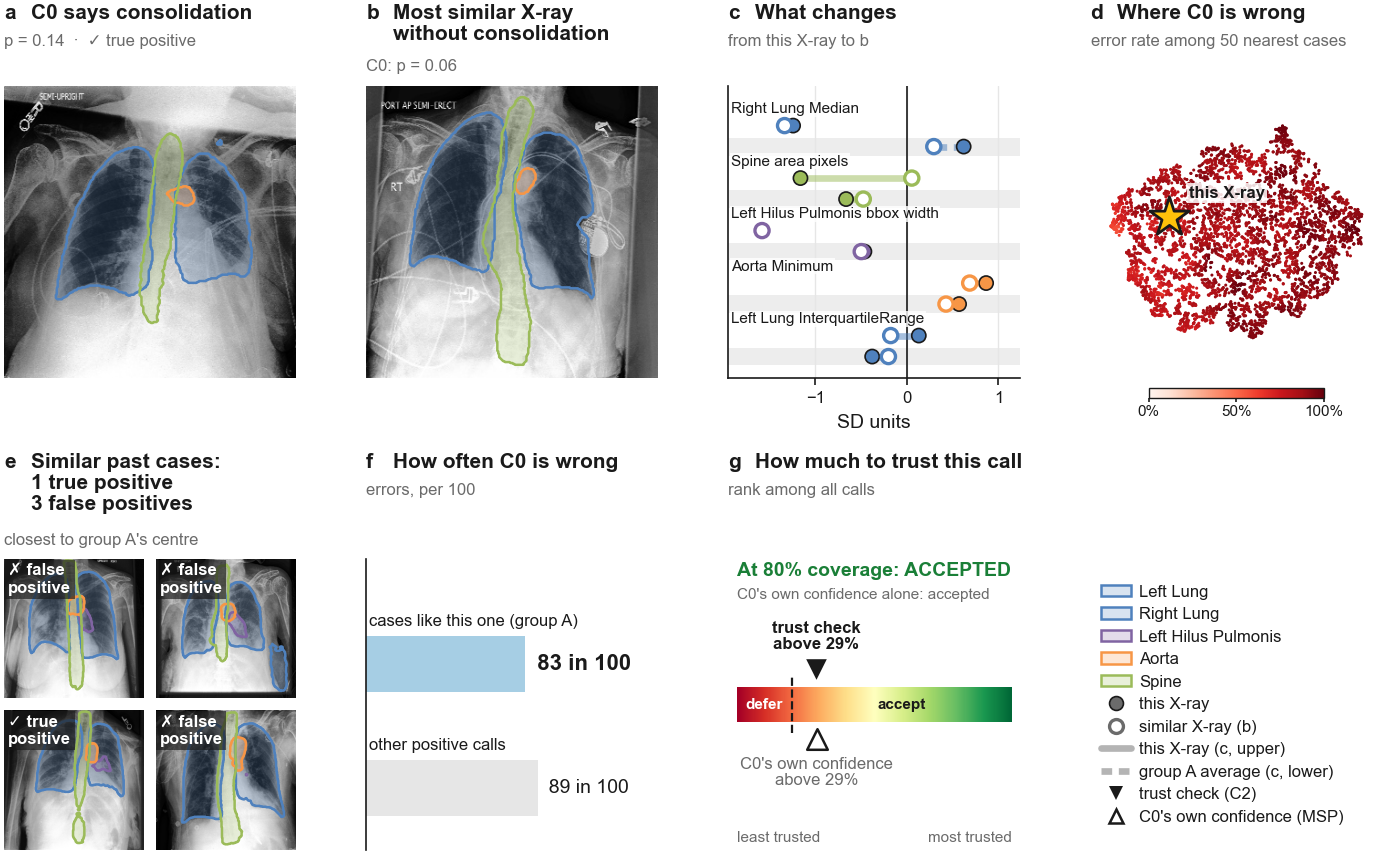

In [15]:
# A reliable case: lowest-error group, C0 was right, clearly on the accept side of the
# global COVERAGE cut (set once, in the case-card cell).
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct", c2=None, c2_cut="accept"))


392 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
80772,4.868,0.330,FP,0.070,0.221,CheXpert-v1.0-small/train/patient44338/study4/...
74581,4.558,0.549,FP,0.013,0.090,CheXpert-v1.0-small/train/patient26691/study8/...
79542,4.123,0.572,FP,0.048,0.027,CheXpert-v1.0-small/train/patient39812/study1/...
79856,4.079,0.445,FP,0.037,0.082,CheXpert-v1.0-small/train/patient41005/study2/...
73153,3.790,0.580,FP,0.065,0.127,CheXpert-v1.0-small/train/patient21858/study16...


C0 says consolidation (p = 0.12)  →  counterfactual p = 0.04  →  group C  →  C2 score lower than 93% of all calls
Cases like this one: 91 in 100 consolidation calls are false positives, vs 84 in 100 for other positive calls
Classifier = C0 (FP). b = counterfactual. g: ▼ C2 percentile 7%, △ MSP percentile 22%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 deferred, MSP accepted
This global cut defers 48% of positive calls with C2 (48% with MSP), not a fixed 20%

saved: figures/xai/consolidation/consolidation_knn_correct_cf_case_positive_groupC_FP_cov80_row80772.{pdf,png,txt}


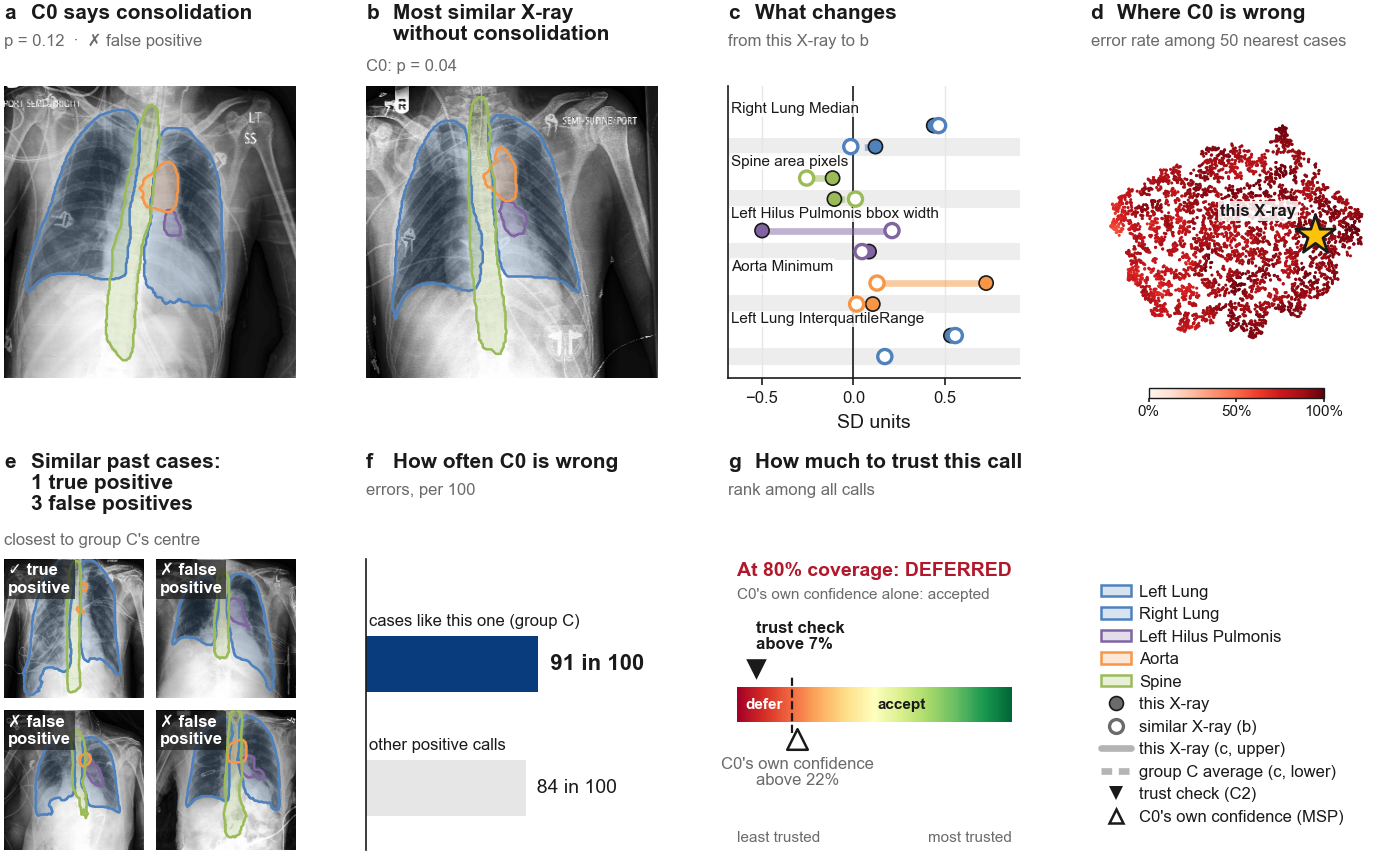

In [16]:
# A risky case: highest-error group, C0 was wrong, and C2 defers it at the global COVERAGE cut.
# MSP is not filtered on: the trust meter shows wherever MSP puts it.
CASE_SIDE = 1            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong",
                              c2=None, c2_cut="defer"))


739 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
66863,4.755,0.452,TN,0.904,0.920,CheXpert-v1.0-small/train/patient00928/study1/...
71240,4.539,0.527,TN,0.894,0.852,CheXpert-v1.0-small/train/patient15362/study1/...
82889,4.431,0.449,TN,0.915,0.708,CheXpert-v1.0-small/train/patient57458/study2/...
80408,4.337,0.483,TN,0.946,0.852,CheXpert-v1.0-small/train/patient42979/study1/...
72845,4.208,0.481,TN,0.899,0.938,CheXpert-v1.0-small/train/patient20836/study5/...


C0 says no consolidation (p = 0.01)  →  counterfactual p = 0.17  →  group A  →  C2 score higher than 90% of all calls
Cases like this one: 1 in 100 no-consolidation calls are false negatives, vs 5 in 100 for other negative calls
Classifier = C0 (TN). b = counterfactual. g: ▼ C2 percentile 90%, △ MSP percentile 92%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 accepted, MSP accepted
This global cut defers 0% of negative calls with C2 (0% with MSP), not a fixed 20%

saved: figures/xai/consolidation/consolidation_knn_correct_cf_case_negative_groupA_TN_cov80_row66863.{pdf,png,txt}


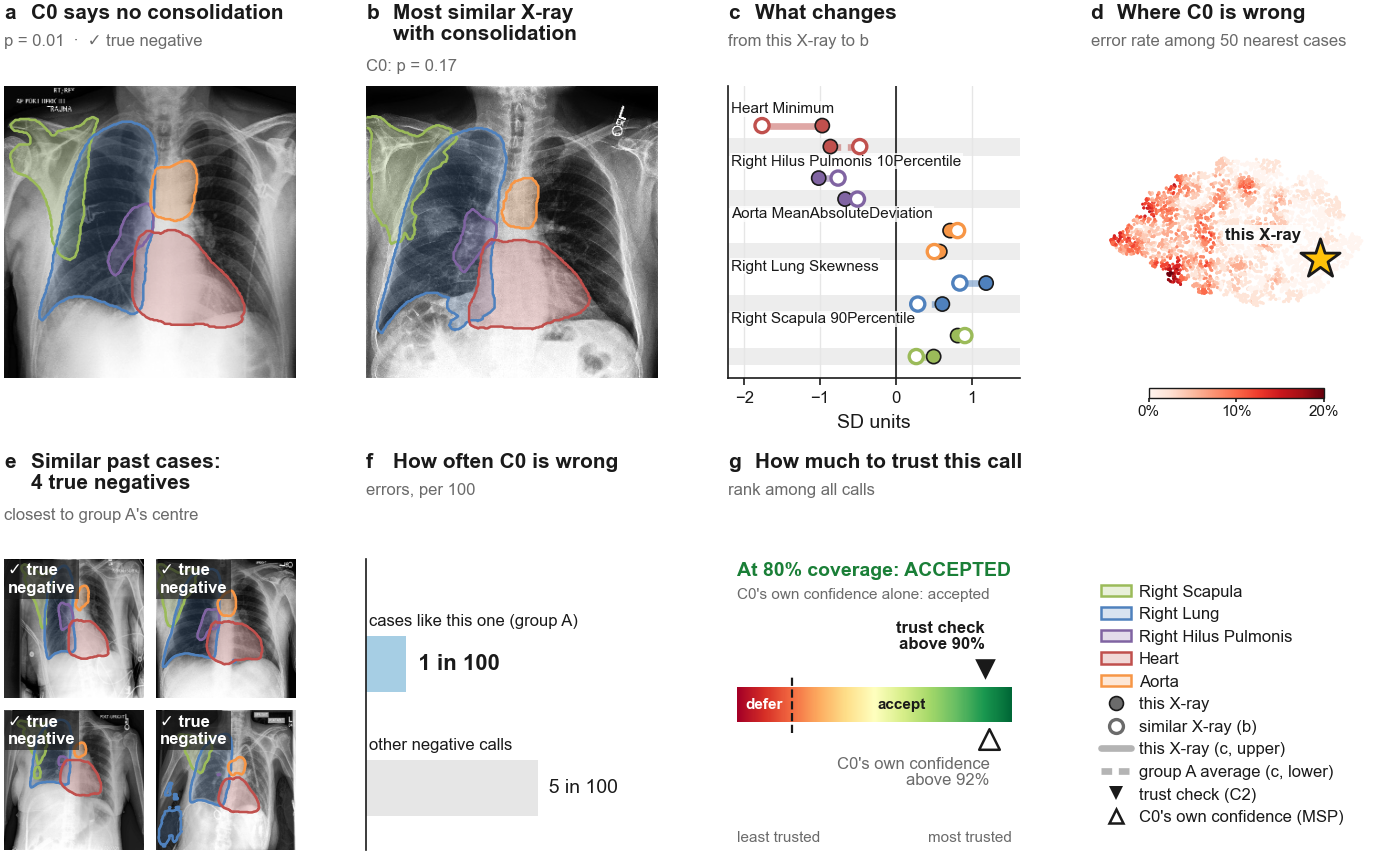

In [17]:
# A reliable negative case: lowest-error group, C0 was right, clearly on the accept side of
# the global COVERAGE cut.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, "A", "correct", c2=None, c2_cut="accept"))



45 candidates


,clearness,profile gap,outcome,C2 rank,MSP rank,path
79320,4.922,0.443,FN,0.475,0.525,CheXpert-v1.0-small/train/patient39374/study23...
70528,3.973,0.611,FN,0.422,0.462,CheXpert-v1.0-small/train/patient12892/study3/...
79345,3.689,0.467,FN,0.484,0.464,CheXpert-v1.0-small/train/patient39412/study4/...
80065,3.636,0.577,FN,0.493,0.498,CheXpert-v1.0-small/train/patient41637/study4/...
82469,3.161,0.698,FN,0.508,0.684,CheXpert-v1.0-small/train/patient54208/study1/...


C0 says no consolidation (p = 0.05)  →  counterfactual p = 0.14  →  group C  →  C2 score lower than 52% of all calls
Cases like this one: 7 in 100 no-consolidation calls are false negatives, vs 2 in 100 for other negative calls
Classifier = C0 (FN). b = counterfactual. g: ▼ C2 percentile 48%, △ MSP percentile 52%, among all calls
At 80% coverage (the 20% least trusted calls in its fold deferred): C2 accepted, MSP accepted
This global cut defers 0% of negative calls with C2 (0% with MSP), not a fixed 20%

saved: figures/xai/consolidation/consolidation_knn_correct_cf_case_negative_groupC_FN_cov80_row79320.{pdf,png,txt}


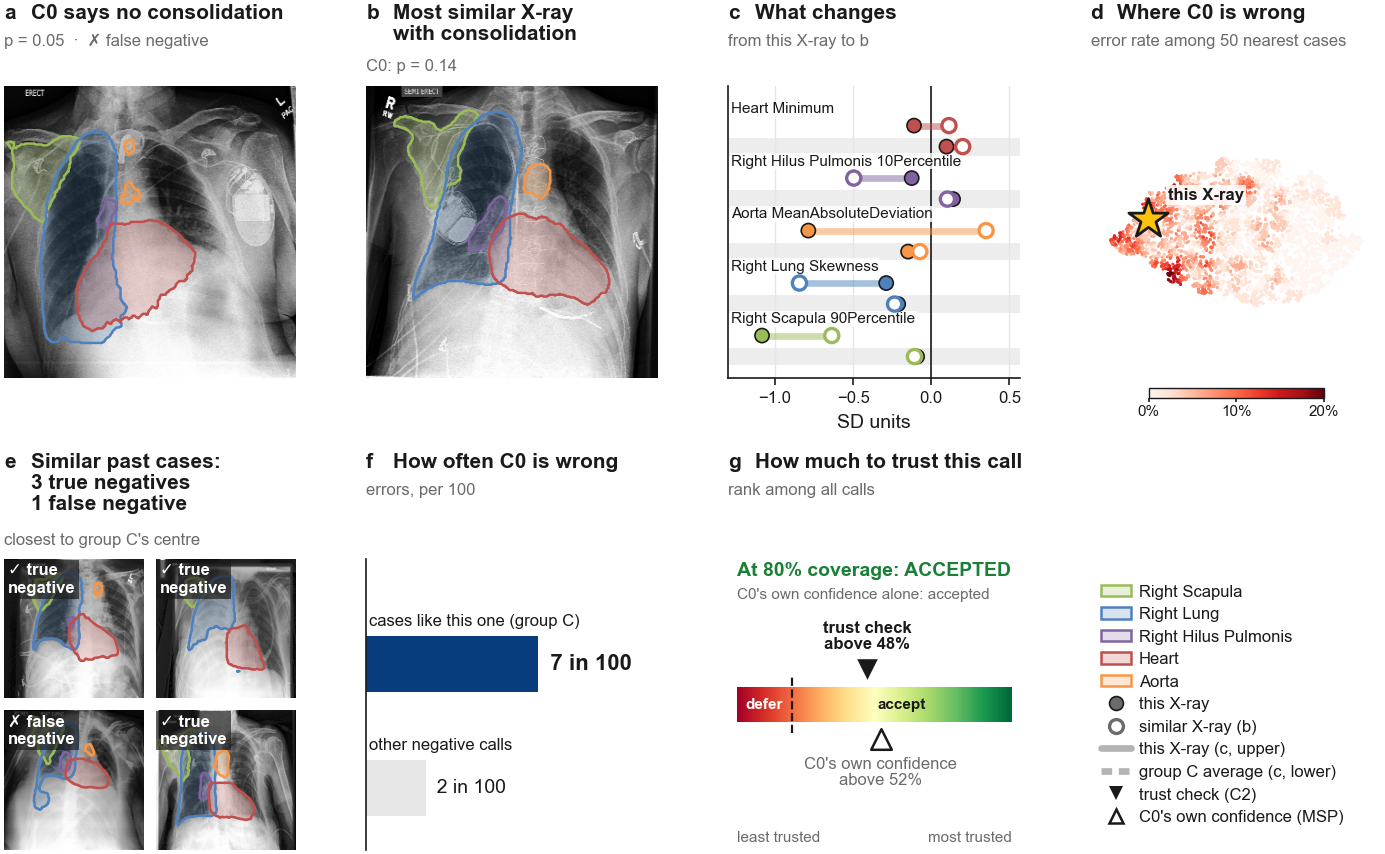

In [18]:
# A risky negative case: highest-error group, C0 missed the disease (false negative). No cut
# filter: when the global COVERAGE cut does not reach the negative calls (cardiomegaly at 80%:
# 0% of them deferred), a deferred false negative does not exist, and the card honestly shows
# even this missed case accepted. Add c2_cut="defer" for diseases where the cut does reach them.
CASE_SIDE = 0            # 0 = C0 said negative, 1 = C0 said positive
case_card(CASE_SIDE, pick_case(CASE_SIDE, LETTERS[N_CLUSTERS - 1], "wrong", c2=None))
